In [ ]:
# 1. Các chỉ số hoá lý nào (độ acid, đường, sulfate, cồn...) ảnh hưởng nhiều nhất đến điểm chất lượng rượu?
# 2. Mô hình nào (Random Forest/XGBoost/Neural Net) dự đoán chất lượng chính xác nhất so với hồi quy tuyến tính gốc?
# 3. Áp dụng SHAP để giải t hích mô hình có giúp phát hiện khác biệt yếu tố ảnh hưởng giữa rượu đỏ và rượu trắng so với paper gốc (vốn không dùng XAI) hay không?

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import sqlite3

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
import os
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split


path = '/content/sample_data'

red = pd.read_csv(path+'/winequality-red.csv', sep=';')
red["wine_type"] = "red"
white = pd.read_csv(path+'/winequality-white.csv', sep=';')
white["wine_type"] = "white"


print("Red wine shape:", red.shape)
print("White wine shape:", white.shape)


Red wine shape: (1599, 13)
White wine shape: (4898, 13)


In [ ]:
red.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [ ]:
# fixed acidity:
# Lượng axit cố định có trong rượu.
# Chỉ số này liên quan đến độ chua và hương vị của rượu.

# volatile acidity:
# Lượng axit dễ bay hơi trong rượu.
# Giá trị quá cao có thể làm giảm chất lượng và tạo mùi không mong muốn.

# citric acid:
# Lượng axit citric có trong rượu.
# Có thể góp phần tạo độ tươi và cân bằng hương vị.

# residual sugar:
# Lượng đường còn lại trong rượu sau quá trình lên men.
# Giá trị cao hơn thường cho thấy rượu có nhiều đường dư hơn.

# chlorides:
# Lượng muối chloride có trong rượu.
# Giá trị quá cao có thể ảnh hưởng tiêu cực đến hương vị.

# free sulfur dioxide:
# Lượng sulfur dioxide (SO2) tự do trong rượu.
# Có tác dụng bảo vệ rượu khỏi quá trình oxy hóa và vi sinh vật.

# total sulfur dioxide:
# Tổng lượng sulfur dioxide (SO2) trong rượu,
# bao gồm cả SO2 tự do và SO2 liên kết.

# density:
# Mật độ của rượu.
# Có liên quan đến hàm lượng đường và alcohol trong rượu.

# pH:
# Đo mức độ axit của rượu.
# Giá trị pH thấp nghĩa là rượu có tính axit cao hơn.

# sulphates:
# Lượng sulphate trong rượu.
# Có thể hỗ trợ quá trình bảo quản và ảnh hưởng đến hương vị.

# alcohol:
# Nồng độ alcohol trong rượu, thường được biểu thị theo phần trăm thể tích.
# Đây là một trong những đặc tính có thể ảnh hưởng đến chất lượng rượu.

# quality:
# Điểm chất lượng của rượu.
# Đây là biến mục tiêu (target variable) mà mô hình machine learning cần dự đoán.

In [ ]:
# Kiểm tra xem có tôn tại nhiều kiểu dữ liệu trong một cột

print("--- Checking Red Wine Data --- ")
for column in red.columns:
    types = red[column].apply(type).unique()
    print(column)
    print(types)
    print()

print("--- Checking White Wine Data --- ")
for column in white.columns:
    types = white[column].apply(type).unique()
    print(column)
    print(types)
    print()

--- Checking Red Wine Data --- 
fixed acidity
[<class 'float'>]

volatile acidity
[<class 'float'>]

citric acid
[<class 'float'>]

residual sugar
[<class 'float'>]

chlorides
[<class 'float'>]

free sulfur dioxide
[<class 'float'>]

total sulfur dioxide
[<class 'float'>]

density
[<class 'float'>]

pH
[<class 'float'>]

sulphates
[<class 'float'>]

alcohol
[<class 'float'>]

quality
[<class 'int'>]

wine_type
[<class 'str'>]

--- Checking White Wine Data --- 
fixed acidity
[<class 'float'>]

volatile acidity
[<class 'float'>]

citric acid
[<class 'float'>]

residual sugar
[<class 'float'>]

chlorides
[<class 'float'>]

free sulfur dioxide
[<class 'float'>]

total sulfur dioxide
[<class 'float'>]

density
[<class 'float'>]

pH
[<class 'float'>]

sulphates
[<class 'float'>]

alcohol
[<class 'float'>]

quality
[<class 'int'>]

wine_type
[<class 'str'>]



In [ ]:
# Kiểm tra số lượng missing value của từng cột của red wine
print("--- Missing Values in Red Wine Data ---")
missing_value_red = red.isnull().sum()
missing_percentage_red = (red.isnull().sum() / len(red)) * 100
missing_summary_red = pd.DataFrame({
    "Missing Values": missing_value_red,
    "Percentage (%)": missing_percentage_red
})
display(missing_summary_red)

# Kiểm tra số lượng missing value của từng cột của white wine
print("\n--- Missing Values in White Wine Data ---")
missing_value_white = white.isnull().sum()
missing_percentage_white = (white.isnull().sum() / len(white)) * 100
missing_summary_white = pd.DataFrame({
    "Missing Values": missing_value_white,
    "Percentage (%)": missing_percentage_white
})
display(missing_summary_white)

# Drop rows with missing values (if any) from both dataframes
red = red.dropna()
white = white.dropna()

print("\nRed wine shape after dropping NaNs:", red.shape)
print("White wine shape after dropping NaNs:", white.shape)

--- Missing Values in Red Wine Data ---


,Missing Values,Percentage (%)
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0



--- Missing Values in White Wine Data ---


,Missing Values,Percentage (%)
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0



Red wine shape after dropping NaNs: (1599, 13)
White wine shape after dropping NaNs: (4898, 13)


In [ ]:
# Kiểm tra trùng lặp dữ liệu cho red wine
print("--- Duplicates in Red Wine Data ---")
duplicate_rows_red = red[red.duplicated(keep=False)].copy()
if not duplicate_rows_red.empty:
    duplicates_red = duplicate_rows_red.sort_values(by=list(red.columns))
    display(duplicates_red)
else:
    print("No duplicate rows found in Red Wine Data.")

# Kiểm tra trùng lặp dữ liệu cho white wine
print("\n--- Duplicates in White Wine Data ---")
duplicate_rows_white = white[white.duplicated(keep=False)].copy()
if not duplicate_rows_white.empty:
    duplicates_white = duplicate_rows_white.sort_values(by=list(white.columns))
    display(duplicates_white)
else:
    print("No duplicate rows found in White Wine Data.")

# Loại bỏ các dòng trùng lặp
red = red.drop_duplicates()
white = white.drop_duplicates()

print("\nRed wine shape after dropping duplicates:", red.shape)
print("White wine shape after dropping duplicates:", white.shape)

--- Duplicates in Red Wine Data ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
142,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6,red
144,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6,red
131,5.6,0.500,0.09,2.3,0.049,17.0,99.0,0.99370,3.63,0.63,13.0,5,red
132,5.6,0.500,0.09,2.3,0.049,17.0,99.0,0.99370,3.63,0.63,13.0,5,red
1488,5.6,0.540,0.04,1.7,0.049,5.0,13.0,0.99420,3.72,0.58,11.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
391,13.7,0.415,0.68,2.9,0.085,17.0,43.0,1.00140,3.06,0.80,10.0,6,red
243,15.0,0.210,0.44,2.2,0.075,10.0,24.0,1.00005,3.07,0.84,9.2,7,red
244,15.0,0.210,0.44,2.2,0.075,10.0,24.0,1.00005,3.07,0.84,9.2,7,red
554,15.5,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,5,red



--- Duplicates in White Wine Data ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
4671,4.9,0.335,0.14,1.3,0.036,69.0,168.0,0.99212,3.47,0.46,10.466667,5,white
4672,4.9,0.335,0.14,1.3,0.036,69.0,168.0,0.99212,3.47,0.46,10.466667,5,white
3941,4.9,0.345,0.34,1.0,0.068,32.0,143.0,0.99138,3.24,0.40,10.100000,5,white
3950,4.9,0.345,0.34,1.0,0.068,32.0,143.0,0.99138,3.24,0.40,10.100000,5,white
2990,5.0,0.270,0.32,4.5,0.032,58.0,178.0,0.98956,3.45,0.31,12.600000,7,white
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2312,9.4,0.280,0.30,1.6,0.045,36.0,139.0,0.99534,3.11,0.49,9.300000,5,white
3094,9.7,0.240,0.49,4.9,0.032,3.0,18.0,0.99368,2.85,0.54,10.000000,6,white
3095,9.7,0.240,0.49,4.9,0.032,3.0,18.0,0.99368,2.85,0.54,10.000000,6,white
1372,10.7,0.220,0.56,8.2,0.044,37.0,181.0,0.99800,2.87,0.68,9.500000,6,white



Red wine shape after dropping duplicates: (1359, 13)
White wine shape after dropping duplicates: (3961, 13)


In [ ]:
# 4. Kiểm tra tính nhất quán cho Red Wine
print("--- Checking Consistency for Red Wine ---")
for column in red.columns:
    print(f"Checking column: {column}")
    nhat_quan = True

    if pd.api.types.is_object_dtype(red[column]) or pd.api.types.is_categorical_dtype(red[column]):
        da_chuan_hoa = red[column].astype(str).str.strip().str.lower()
        if da_chuan_hoa.nunique() != red[column].nunique():
            nhat_quan = False
            print("  KHÔNG nhất quán (có khoảng trắng / chữ hoa-thường không đồng nhất)")
        else:
            print("  Dường như nhất quán")
        print(f"  Số giá trị duy nhất: {red[column].nunique()}")
    else:
        print("  Dường như nhất quán (kiểu số/ngày tháng)")
    print()

# 4. Kiểm tra tính nhất quán cho White Wine
print("\n--- Checking Consistency for White Wine ---")
for column in white.columns:
    print(f"Checking column: {column}")
    nhat_quan = True

    if pd.api.types.is_object_dtype(white[column]) or pd.api.types.is_categorical_dtype(white[column]):
        da_chuan_hoa = white[column].astype(str).str.strip().str.lower()
        if da_chuan_hoa.nunique() != white[column].nunique():
            nhat_quan = False
            print("  KHÔNG nhất quán (có khoảng trắng / chữ hoa-thường không đồng nhất)")
        else:
            print("  Dường như nhất quán")
        print(f"  Số giá trị duy nhất: {white[column].nunique()}")
    else:
        print("  Dường như nhất quán (kiểu số/ngày tháng)")
    print()

--- Checking Consistency for Red Wine ---
Checking column: fixed acidity
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: volatile acidity
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: citric acid
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: residual sugar
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: chlorides
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: free sulfur dioxide
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: total sulfur dioxide
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: density
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: pH
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: sulphates
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: alcohol
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: quality
  Dường như nhất quán (kiểu số/ngày tháng)

Checking column: wine_type
  Dường như nhất quán
  Số giá trị duy nhất: 1


--- 

/tmp/ipykernel_979/3452607916.py:7: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_object_dtype(red[column]) or pd.api.types.is_categorical_dtype(red[column]):
/tmp/ipykernel_979/3452607916.py:25: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_object_dtype(white[column]) or pd.api.types.is_categorical_dtype(white[column]):


In [ ]:
# kiểm tra outlier có tồn tại hay không trong red wine
print("--- Outliers in Red Wine Data ---")
numeric_cols_red = red.select_dtypes(include="number").columns

Q1_red = red[numeric_cols_red].quantile(0.25)
Q3_red = red[numeric_cols_red].quantile(0.75)

IQR_red = Q3_red - Q1_red

lower_bound_red = Q1_red - 1.5 * IQR_red
upper_bound_red = Q3_red + 1.5 * IQR_red

outliers_red = ((red[numeric_cols_red] < lower_bound_red) | (red[numeric_cols_red] > upper_bound_red)).sum()

print("Number of outliers in each column (Red Wine):")
display(outliers_red)

# kiểm tra outlier có tồn tại hay không trong white wine
print("\n--- Outliers in White Wine Data ---")
numeric_cols_white = white.select_dtypes(include="number").columns

Q1_white = white[numeric_cols_white].quantile(0.25)
Q3_white = white[numeric_cols_white].quantile(0.75)

IQR_white = Q3_white - Q1_white

lower_bound_white = Q1_white - 1.5 * IQR_white
upper_bound_white = Q3_white + 1.5 * IQR_white

outliers_white = ((white[numeric_cols_white] < lower_bound_white) | (white[numeric_cols_white] > upper_bound_white)).sum()

print("Number of outliers in each column (White Wine):")
display(outliers_white)

# Một số biến có khá nhiều giá trị nằm ngoài khoảng IQR.
# Các giá trị này không được loại bỏ vì chúng có thể đại diện cho sự khác biệt thực tế trong đặc tính hóa lý của rượu thay vì lỗi dữ liệu.
# Vì vậy những outliers này nên giữ lại để xem như là yếu tố ảnh hưởng quality

--- Outliers in Red Wine Data ---
Number of outliers in each column (Red Wine):


,0
fixed acidity,41
volatile acidity,19
citric acid,1
residual sugar,126
chlorides,87
free sulfur dioxide,26
total sulfur dioxide,45
density,35
pH,28
sulphates,55



--- Outliers in White Wine Data ---
Number of outliers in each column (White Wine):


,0
fixed acidity,106
volatile acidity,133
citric acid,223
residual sugar,16
chlorides,178
free sulfur dioxide,44
total sulfur dioxide,14
density,6
pH,46
sulphates,96


In [ ]:
# kiểm tra độ lệch của từng cột cho red wine
print("--- Skewness for Red Wine Data ---")
numeric_cols_red = red.select_dtypes(include='number').columns

for column in numeric_cols_red:
    skewness_red = red[column].skew()

    if abs(skewness_red) < 0.5:
        distribution_red = "Approximately balanced"
    elif abs(skewness_red) < 1:
        distribution_red = "Moderately skewed"
    else:
        distribution_red = "Highly skewed"

    print(f"{column}:")
    print(f"  Skewness = {skewness_red:.2f}")
    print(f"  Distribution = {distribution_red}")
    print()

# kiểm tra độ lệch của từng cột cho white wine
print("\n--- Skewness for White Wine Data ---")
numeric_cols_white = white.select_dtypes(include='number').columns

for column in numeric_cols_white:
    skewness_white = white[column].skew()

    if abs(skewness_white) < 0.5:
        distribution_white = "Approximately balanced"
    elif abs(skewness_white) < 1:
        distribution_white = "Moderately skewed"
    else:
        distribution_white = "Highly skewed"

    print(f"{column}:")
    print(f"  Skewness = {skewness_white:.2f}")
    print(f"  Distribution = {distribution_white}")
    print()

--- Skewness for Red Wine Data ---
fixed acidity:
  Skewness = 0.94
  Distribution = Moderately skewed

volatile acidity:
  Skewness = 0.73
  Distribution = Moderately skewed

citric acid:
  Skewness = 0.31
  Distribution = Approximately balanced

residual sugar:
  Skewness = 4.55
  Distribution = Highly skewed

chlorides:
  Skewness = 5.50
  Distribution = Highly skewed

free sulfur dioxide:
  Skewness = 1.23
  Distribution = Highly skewed

total sulfur dioxide:
  Skewness = 1.54
  Distribution = Highly skewed

density:
  Skewness = 0.04
  Distribution = Approximately balanced

pH:
  Skewness = 0.23
  Distribution = Approximately balanced

sulphates:
  Skewness = 2.41
  Distribution = Highly skewed

alcohol:
  Skewness = 0.86
  Distribution = Moderately skewed

quality:
  Skewness = 0.19
  Distribution = Approximately balanced


--- Skewness for White Wine Data ---
fixed acidity:
  Skewness = 0.70
  Distribution = Moderately skewed

volatile acidity:
  Skewness = 1.64
  Distribution =

In [ ]:
# các cột đặc tính kèm dơn vị và cột mục tiêu cho red wine
X_red = red.drop(["quality", "wine_type"], axis=1)
y_red = red["quality"]

# các cột đặc tính kèm dơn vị và cột mục tiêu cho white wine
X_white = white.drop(["quality", "wine_type"], axis=1)
y_white = white["quality"]

feature_units = {
    "fixed acidity": "g/dm³",
    "volatile acidity": "g/dm³",
    "citric acid": "g/dm³",
    "residual sugar": "g/dm³",
    "chlorides": "g/dm³",
    "free sulfur dioxide": "mg/dm³",
    "total sulfur dioxide": "mg/dm³",
    "density": "g/cm³",
    "pH": "unitless",
    "sulphates": "g/dm³",
    "alcohol": "% vol."
}

print("Features with Units for Red Wine:")
for feature in X_red.columns.tolist():
    unit = feature_units.get(feature, "N/A (Unit not specified)")
    print(f"- {feature}: {unit}")

print("\nTarget for Red Wine:")
print(y_red.name)

print("\nFeatures with Units for White Wine:")
for feature in X_white.columns.tolist():
    unit = feature_units.get(feature, "N/A (Unit not specified)")
    print(f"- {feature}: {unit}")

print("\nTarget for White Wine:")
print(y_white.name)

Features with Units for Red Wine:
- fixed acidity: g/dm³
- volatile acidity: g/dm³
- citric acid: g/dm³
- residual sugar: g/dm³
- chlorides: g/dm³
- free sulfur dioxide: mg/dm³
- total sulfur dioxide: mg/dm³
- density: g/cm³
- pH: unitless
- sulphates: g/dm³
- alcohol: % vol.

Target for Red Wine:
quality

Features with Units for White Wine:
- fixed acidity: g/dm³
- volatile acidity: g/dm³
- citric acid: g/dm³
- residual sugar: g/dm³
- chlorides: g/dm³
- free sulfur dioxide: mg/dm³
- total sulfur dioxide: mg/dm³
- density: g/cm³
- pH: unitless
- sulphates: g/dm³
- alcohol: % vol.

Target for White Wine:
quality


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Apply the scaler to the red wine features
X_red_scaled = scaler.fit_transform(X_red)
X_red_scaled_df = pd.DataFrame(X_red_scaled, columns=X_red.columns)

# Apply the scaler to the white wine features
X_white_scaled = scaler.fit_transform(X_white)
X_white_scaled_df = pd.DataFrame(X_white_scaled, columns=X_white.columns)

print("Scaled X_red head (MinMaxScaler to 0-1 range):")
display(X_red_scaled_df.head())
print("\nScaled X_white head (MinMaxScaler to 0-1 range):")
display(X_white_scaled_df.head())

Scaled X_red head (MinMaxScaler to 0-1 range):


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385
4,0.247788,0.369863,0.00,0.061644,0.105175,0.169014,0.120141,0.567548,0.606299,0.137725,0.153846



Scaled X_white head (MinMaxScaler to 0-1 range):


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.307692,0.186275,0.216867,0.308282,0.106825,0.149826,0.373550,0.267785,0.254545,0.267442,0.129032
1,0.240385,0.215686,0.204819,0.015337,0.118694,0.041812,0.285383,0.132832,0.527273,0.313953,0.241935
2,0.413462,0.196078,0.240964,0.096626,0.121662,0.097561,0.204176,0.154039,0.490909,0.255814,0.338710
3,0.326923,0.147059,0.192771,0.121166,0.145401,0.156794,0.410673,0.163678,0.427273,0.209302,0.306452
4,0.230769,0.235294,0.096386,0.098160,0.106825,0.097561,0.294664,0.150183,0.418182,0.290698,0.258065


In [ ]:
import sqlite3
import pandas as pd

# Create SQLite database connection
link = sqlite3.connect("wine_quality.db")

# Combine the red and white wine dataframes into a single 'wine' dataframe
wine = pd.concat([red, white], ignore_index=True)

# Save the combined DataFrame as a SQLite table named 'wine_quality'
wine.to_sql("wine_quality", link, if_exists="replace", index=False)

print("Data successfully combined and saved to SQLite!")

Data successfully combined and saved to SQLite!


In [ ]:
wine.to_sql(
    'wine_quality',
    link,
    if_exists='replace',
    index=False
)

5320

/tmp/ipykernel_979/2380719639.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='quality', y='number_of_wines', data=result, palette='viridis')


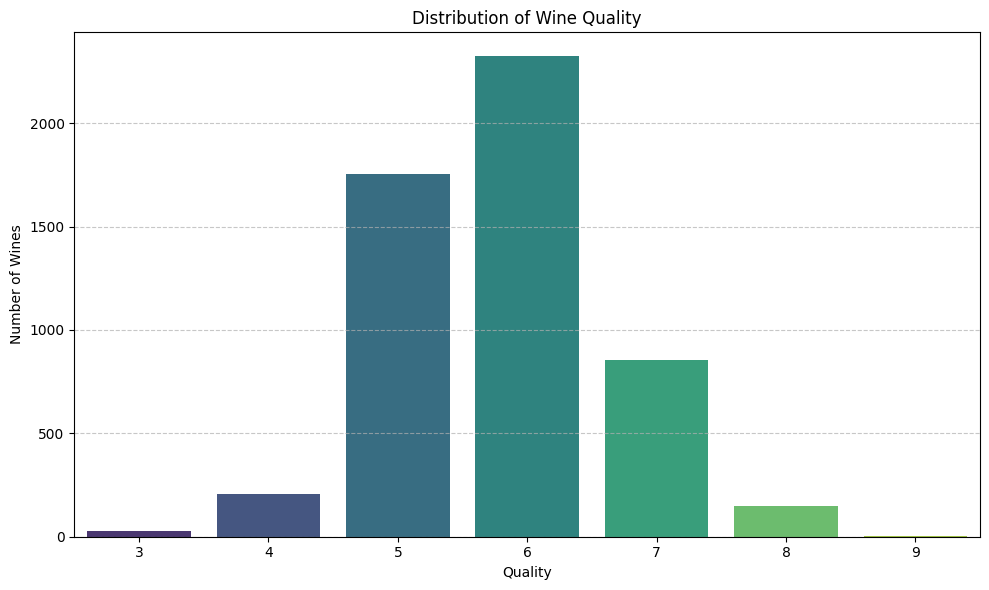

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# test
query = """
SELECT quality, COUNT(*) AS number_of_wines
FROM wine_quality
GROUP BY quality
ORDER BY quality;
"""

result = pd.read_sql_query(query, link)

# Plot the results
plt.figure(figsize=(10, 6))
sns.barplot(x='quality', y='number_of_wines', data=result, palette='viridis')
plt.title('Distribution of Wine Quality')
plt.xlabel('Quality')
plt.ylabel('Number of Wines')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
query = """
SELECT
    quality,
    AVG("fixed acidity") AS avg_fixed_acidity,
    AVG("volatile acidity") AS avg_volatile_acidity,
    AVG("citric acid") AS avg_citric_acid,
    AVG("residual sugar") AS avg_residual_sugar,
    AVG(chlorides) AS avg_chlorides,
    AVG("free sulfur dioxide") AS avg_free_sulfur_dioxide,
    AVG("total sulfur dioxide") AS avg_total_sulfur_dioxide,
    AVG(density) AS avg_density,
    AVG(pH) AS avg_pH,
    AVG(sulphates) AS avg_sulphates,
    AVG(alcohol) AS avg_alcohol
FROM wine_quality
WHERE wine_type = 'white'
GROUP BY quality
ORDER BY quality;
"""

# Execute the query and load results into a DataFrame
quality_averages = pd.read_sql_query(query, link)

# Display the results
print("Average physicochemical indicators grouped by quality for white wine:")
display(quality_averages)

Average physicochemical indicators grouped by quality for white wine:


,quality,avg_fixed_acidity,avg_volatile_acidity,avg_citric_acid,avg_residual_sugar,avg_chlorides,avg_free_sulfur_dioxide,avg_total_sulfur_dioxide,avg_density,avg_pH,avg_sulphates,avg_alcohol
0,3,7.600000,0.333250,0.336000,6.392500,0.054300,53.325000,170.600000,0.994884,3.187500,0.474500,10.345000
1,4,7.139869,0.382157,0.305229,4.499346,0.050059,23.127451,124.127451,0.994199,3.185425,0.476667,10.197712
2,5,6.921745,0.303306,0.335957,6.941532,0.052323,36.002979,150.099574,0.995072,3.171779,0.482621,9.864182
3,6,6.819435,0.261630,0.338227,5.959787,0.045178,35.308166,136.460850,0.993722,3.196029,0.492355,10.646122
4,7,6.701089,0.265363,0.327358,4.523875,0.037556,33.851234,122.052975,0.992059,3.228462,0.502859,11.515844
5,8,6.609924,0.286794,0.335038,5.056489,0.036756,35.618321,122.034351,0.991745,3.235115,0.485878,11.880153
6,9,7.420000,0.298000,0.386000,4.120000,0.027400,33.400000,116.000000,0.991460,3.308000,0.466000,12.180000


In [ ]:
# Trung bình các chỉ số hoá lý theo Quality

# Bảng này thể hiện giá trị trung bình của 11 chỉ số hoá lý đối với rượu trắng, phân nhóm theo điểm quality (từ 3 đến 9).
# Nhìn qua từng hàng, ta thấy được thành phần hoá học thay đổi như thế nào khi chất lượng rượu tăng lên.

# XU HƯỚNG MẠNH, RÕ RÀNG

# Alcohol (nồng độ cồn) tăng rõ rệt khi quality tăng:
# 10.35 (Q3) -> 10.15 (Q4) -> 9.81 (Q5) -> 10.58 (Q6) -> 11.37 (Q7) -> 11.64 (Q8) -> 12.18 (Q9)
# Ngoại trừ giảm nhẹ ở Q4-Q5, đà tăng từ Q5 đến Q9 khá dốc và ổn định.
# Đây là xu hướng mạnh và rõ ràng nhất trong bảng -- rượu điểm cao có xu hướng
# nồng độ cồn cao hơn rõ rệt, có thể phản ánh nho chín kỹ hơn khi thu hoạch và
# rượu có vị "đầy đặn" (full-bodied) hơn, được hội đồng chấm điểm cao hơn.

# Density (tỷ trọng) giảm đều:
# 0.9949 (Q3) -> 0.9943 (Q4) -> 0.9953 (Q5) -> 0.9940 (Q6)
# -> 0.9925 (Q7) -> 0.9922 (Q8) -> 0.9915 (Q9)
# Xu hướng này gần như đối nghịch với alcohol -- cồn nhẹ hơn nước,
# nên khi nồng độ cồn tăng thì tỷ trọng tự nhiên giảm theo.

# Volatile Acidity (acid bay hơi) giảm từ Q4 đến Q7:
# 0.381 (Q4) -> 0.302 (Q5) -> 0.261 (Q6) -> 0.263 (Q7)
# rồi tăng nhẹ trở lại ở Q8-Q9. Acid bay hơi (chủ yếu là acid acetic)
# tạo mùi giống giấm, nên giá trị càng thấp thường cho thấy rượu
# càng "sạch mùi", chất lượng làm rượu tốt hơn

# XU HƯỚNG TRUNG BÌNH

# Total Sulfur Dioxide (tổng SO2) giảm khá đều:
# 170.6 (Q3) -> 150.9 (Q5) -> 137.0 (Q6) -> 125.1 (Q7)
# -> 116.0 (Q9)
# SO2 dùng làm chất bảo quản; xu hướng giảm cho thấy rượu
# chất lượng cao có thể cần ít can thiệp hoá chất hơn.

# Chlorides (muối chloride) cũng có xu hướng giảm:
# 0.054 (Q3) -> 0.045 (Q6) -> 0.027 (Q9)
# Chloride thấp hơn liên quan đến việc rượu ít bị mặn không mong muốn.

# XU HƯỚNG YẾU HOẶC KHÔNG RÕ RÀNG

# pH chỉ tăng nhẹ (3.17-3.31 trong toàn bộ khoảng), fixed acidity
# giảm nhẹ nhưng không theo quy luật rõ ràng, và free sulfur dioxide
# thì dao động thất thường:
# 53.3 -> 23.4 -> 36.4 -> 35.7 -> 34.1 -> 36.7 -> 33.4
# hoàn toàn không có chiều hướng nhất quán.

# Residual Sugar (đường), Citric Acid, và Sulphates gần như
# đi ngang ở mọi mức quality:
# đường: 4.1-7.3, citric acid: 0.30-0.39, sulphates: 0.47-0.50
# cho thấy các chỉ số này ít có quan hệ tuyến tính trực tiếp
# với chất lượng khi xét riêng lẻ.

Number of wine samples by quality category and type:


,wine_type,quality_category,number_of_samples
0,red,Low,63
1,red,Medium,1112
2,red,High,184
3,white,Low,173
4,white,Medium,2963
5,white,High,825


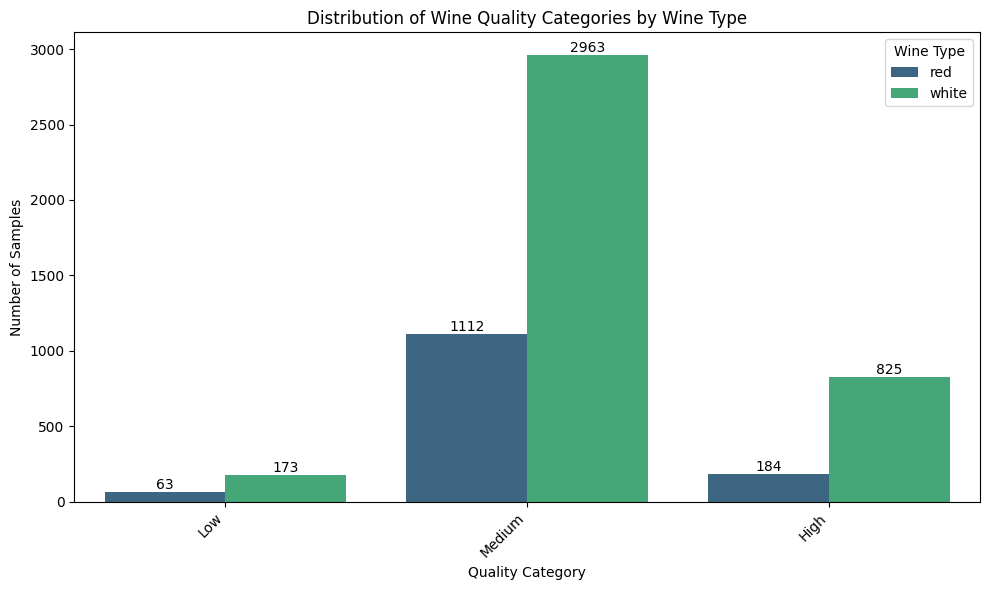

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

query_quality_categories = """
SELECT
    wine_type,
    CASE
        WHEN quality <= 4 THEN 'Low'
        WHEN quality BETWEEN 5 AND 6 THEN 'Medium'
        WHEN quality >= 7 THEN 'High'
        ELSE 'Unknown'
    END AS quality_category,
    COUNT(*) AS number_of_samples
FROM wine_quality
GROUP BY wine_type, quality_category
ORDER BY
    wine_type,
    CASE quality_category
        WHEN 'Low' THEN 1
        WHEN 'Medium' THEN 2
        WHEN 'High' THEN 3
        ELSE 4
    END;
"""

quality_category_counts = pd.read_sql_query(query_quality_categories, link)

print("Number of wine samples by quality category and type:")
display(quality_category_counts)

# Create a single bar chart with 'wine_type' as hue
plt.figure(figsize=(10, 6))
sns.barplot(
    x='quality_category',
    y='number_of_samples',
    hue='wine_type',
    data=quality_category_counts,
    palette='viridis',
    order=['Low', 'Medium', 'High'] # Ensure consistent order
)

# Add labels on top of the bars
ax = plt.gca() # Get the current axes
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')

plt.title('Distribution of Wine Quality Categories by Wine Type')
plt.xlabel('Quality Category')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Wine Type')
plt.tight_layout()
plt.show()

In [ ]:
query_max_values = """
SELECT
    quality,
    MAX("fixed acidity") AS max_fixed_acidity,
    MAX("volatile acidity") AS max_volatile_acidity,
    MAX("citric acid") AS max_citric_acid,
    MAX("residual sugar") AS max_residual_sugar,
    MAX(chlorides) AS max_chlorides,
    MAX("free sulfur dioxide") AS max_free_sulfur_dioxide,
    MAX("total sulfur dioxide") AS max_total_sulfur_dioxide,
    MAX(density) AS max_density,
    MAX(pH) AS max_pH,
    MAX(sulphates) AS max_sulphates,
    MAX(alcohol) AS max_alcohol
FROM wine_quality
WHERE wine_type = 'white'
GROUP BY quality
ORDER BY quality;
"""

max_values_by_quality = pd.read_sql_query(query_max_values, link)
display(max_values_by_quality)

,quality,max_fixed_acidity,max_volatile_acidity,max_citric_acid,max_residual_sugar,max_chlorides,max_free_sulfur_dioxide,max_total_sulfur_dioxide,max_density,max_pH,max_sulphates,max_alcohol
0,3,11.8,0.640,0.47,16.20,0.244,289.0,440.0,1.00010,3.55,0.74,12.6
1,4,10.2,1.100,0.88,17.55,0.290,138.5,272.0,1.00040,3.72,0.87,13.5
2,5,10.3,0.905,1.00,23.50,0.346,131.0,344.0,1.00241,3.79,0.88,13.6
3,6,14.2,0.965,1.66,65.80,0.255,112.0,294.0,1.03898,3.81,1.06,14.0
4,7,9.2,0.760,0.74,19.25,0.135,108.0,229.0,1.00040,3.82,1.08,14.2
5,8,8.2,0.660,0.74,14.80,0.121,105.0,212.5,1.00060,3.59,0.95,14.0
6,9,9.1,0.360,0.49,10.60,0.035,57.0,139.0,0.99700,3.41,0.61,12.9


In [ ]:
sql_query_red = """
SELECT
    AVG(`fixed acidity`) AS avg_fixed_acidity,
    AVG(`volatile acidity`) AS avg_volatile_acidity,
    AVG(`citric acid`) AS avg_citric_acid,
    AVG(`residual sugar`) AS avg_residual_sugar,
    AVG(chlorides) AS avg_chlorides,
    AVG(`free sulfur dioxide`) AS avg_free_sulfur_dioxide,
    AVG(`total sulfur dioxide`) AS avg_total_sulfur_dioxide,
    AVG(density) AS avg_density,
    AVG(pH) AS avg_pH,
    AVG(sulphates) AS avg_sulphates,
    AVG(alcohol) AS avg_alcohol
FROM wine_quality
WHERE wine_type = 'red';
"""

data_red_mean = pd.read_sql_query(sql_query_red, link)

#print(data_red_mean.T)
display(data_red_mean)

,avg_fixed_acidity,avg_volatile_acidity,avg_citric_acid,avg_residual_sugar,avg_chlorides,avg_free_sulfur_dioxide,avg_total_sulfur_dioxide,avg_density,avg_pH,avg_sulphates,avg_alcohol
0,8.310596,0.529478,0.272333,2.5234,0.088124,15.893304,46.825975,0.996709,3.309787,0.658705,10.432315


In [ ]:
# So sánh chỉ số hóa lý giữa các chất lượng rượu

sql_query_quality = """
SELECT
    CASE
        WHEN quality <= 4 THEN 'Low Quality'
        WHEN quality BETWEEN 5 AND 6 THEN 'Medium Quality'
        WHEN quality >= 7 THEN 'High Quality'
    END AS quality_group,

    AVG(`fixed acidity`) AS fixed_acidity,
    AVG(`volatile acidity`) AS volatile_acidity,
    AVG(`citric acid`) AS citric_acid,
    AVG(`residual sugar`) AS residual_sugar,
    AVG(chlorides) AS chlorides,
    AVG(`free sulfur dioxide`) AS free_sulfur_dioxide,
    AVG(`total sulfur dioxide`) AS total_sulfur_dioxide,
    AVG(density) AS density,
    AVG(pH) AS pH,
    AVG(sulphates) AS sulphates,
    AVG(alcohol) AS alcohol

FROM wine_quality

GROUP BY
    CASE
        WHEN quality <= 4 THEN 'Low Quality'
        WHEN quality BETWEEN 5 AND 6 THEN 'Medium Quality'
        WHEN quality >= 7 THEN 'High Quality'
    END
ORDER BY
    CASE
        WHEN quality_group = 'Low Quality' THEN 1
        WHEN quality_group = 'Medium Quality' THEN 2
        WHEN quality_group = 'High Quality' THEN 3
    END;
"""

# Lấy dữ liệu từ SQL
quality = pd.read_sql_query(sql_query_quality, link)

# Làm tròn 2 chữ số
quality = quality.round(2)

# Hiển thị kết quả
print("So sánh chỉ số hóa lý giữa rượu chất lượng thấp và cao:")
print(quality)

So sánh chỉ số hóa lý giữa rượu chất lượng thấp và cao:
    quality_group  fixed_acidity  volatile_acidity  citric_acid  \
0     Low Quality           7.37              0.47         0.27   
1  Medium Quality           7.24              0.35         0.32   
2    High Quality           7.08              0.29         0.34   

   residual_sugar  chlorides  free_sulfur_dioxide  total_sulfur_dioxide  \
0            4.18       0.06                22.73                104.12   
1            5.29       0.06                30.36                116.64   
2            4.26       0.04                30.45                106.21   

   density    pH  sulphates  alcohol  
0     0.99  3.24       0.51    10.22  
1     0.99  3.22       0.53    10.32  
2     0.99  3.24       0.54    11.57  


In [ ]:
# Phân nhóm Chất lượng Rượu (Low / Medium / High) - Rượu Trắng

# Dataset gốc có điểm quality từ 3 đến 9 (7 mức)
# Để dễ phân tích và trình bày hơn, ta gộp lại thành 3 nhóm lớn:
# Low: quality từ 3 đến 4
# Medium: quality từ 5 đến 7
# High: quality từ 8 đến 9
# Đếm số lượng mẫu trong từng nhóm (Low / Medium / High).

# Trước khi đưa dữ liệu vào huấn luyện mô hình AI (Random Forest, XGBoost,...), cần kiểm tra xem
# số lượng mẫu giữa các nhóm có cân bằng không.
# Nếu một nhóm có quá ít mẫu (ví dụ nhóm "High" chỉ có vài trăm, trong khi "Medium" có hàng nghìn), mô hình sẽ có xu hướng "học lệch".
# Nó dự đoán tốt cho nhóm nhiều dữ liệu nhưng dự đoán kém cho nhóm ít dữ liệu.
# Đây là bước kiểm tra quan trọng cần làm trước khi xây dựng mô hình.

# ORDER BY
# máy tính sắp xếp chữ theo bảng chữ cái, điều này sẽ sắp xếp sai thành: High - Low - Medium.
# Để hiển thị đúng thứ tự logic (Low -> Medium -> High), ta gán một số thứ tự
# cho từng nhóm: Low = 1, Medium = 2, High = 3, rồi sắp xếp theo con số này thay vì theo chữ cái.

In [ ]:
sql_query_alcohol = """
SELECT
    wine_type,
    AVG(alcohol) AS avg_alcohol
FROM wine_quality
WHERE wine_type IN ('red', 'white')
GROUP BY wine_type;
"""

alcohol = pd.read_sql_query(sql_query_alcohol, link)

alcohol = alcohol.round(2)

print("So sánh hàm lượng Alcohol giữa Red Wine và White Wine:")
print(alcohol)

So sánh hàm lượng Alcohol giữa Red Wine và White Wine:
  wine_type  avg_alcohol
0       red        10.43
1     white        10.59


In [ ]:
# Filter the wine data to include only qualities between 1 and 9 (inclusive)
wine_filtered = wine[(wine['quality'] >= 3) & (wine['quality'] <= 9)].copy()

X = wine_filtered.drop(columns=["quality", "wine_type"],axis=1)

# Categorize 'quality' into 3 layers:
# Layer 0: quality 3-4 (Low)
# Layer 1: quality 5-7 (Medium)
# Layer 2: quality 8-9 (High)
bins = [2, 4, 6, 9] # Define bins for quality scores
labels = ['Low', 'Medium', 'High'] # Assign numerical labels for the categories
y = pd.cut(wine_filtered["quality"], bins=bins, labels=labels, right=True, include_lowest=True)

# Convert categorical labels to numerical codes for machine learning models and ensure it's an integer type
y = y.cat.codes.astype(int)

In [ ]:
# Split data for Red Wine
X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(
    X_red_scaled_df, y_red, test_size=0.2, random_state=42
)

# Split data for White Wine
X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(
    X_white_scaled_df, y_white, test_size=0.2, random_state=42
)

# The 'y' labels are already 0-indexed (0, 1, 2) after pd.cut, so no further adjustment is needed.
# These variables were previously defined for a combined dataset and are now redundant or need to be redefined
# if a combined model is still intended later. For separate analysis, they are not needed.
# y_train_xgboost = y_train
# y_test_xgboost = y_test

print("Red Wine data split into training and testing sets.")
print(f"X_red_train shape: {X_red_train.shape}")
print(f"y_red_train shape: {y_red_train.shape}")
print(f"X_red_test shape: {X_red_test.shape}")
print(f"y_red_test shape: {y_red_test.shape}")

print("\nWhite Wine data split into training and testing sets.")
print(f"X_white_train shape: {X_white_train.shape}")
print(f"y_white_train shape: {y_white_train.shape}")
print(f"X_white_test shape: {X_white_test.shape}")
print(f"y_white_test shape: {y_white_test.shape}")


Red Wine data split into training and testing sets.
X_red_train shape: (1087, 11)
y_red_train shape: (1087,)
X_red_test shape: (272, 11)
y_red_test shape: (272,)

White Wine data split into training and testing sets.
X_white_train shape: (3168, 11)
y_white_train shape: (3168,)
X_white_test shape: (793, 11)
y_white_test shape: (793,)


In [ ]:
smote = SMOTE(random_state=42, k_neighbors=3)

# Apply SMOTE for Red Wine
X_red_train_smote, y_red_train_smote = smote.fit_resample(
     X_red_train,
     y_red_train
)

print("Red Wine training data reshaped with SMOTE.")
print(f"X_red_train_smote shape: {X_red_train_smote.shape}")
print(f"y_red_train_smote shape: {y_red_train_smote.shape}")

Red Wine training data reshaped with SMOTE.
X_red_train_smote shape: (2742, 11)
y_red_train_smote shape: (2742,)


In [ ]:
# Apply SMOTE for White Wine
X_white_train_smote, y_white_train_smote = smote.fit_resample(
     X_white_train,
     y_white_train
)

print("White Wine training data reshaped with SMOTE.")
print(f"X_white_train_smote shape: {X_white_train_smote.shape}")
print(f"y_white_train_smote shape: {y_white_train_smote.shape}")

White Wine training data reshaped with SMOTE.
X_white_train_smote shape: (10073, 11)
y_white_train_smote shape: (10073,)


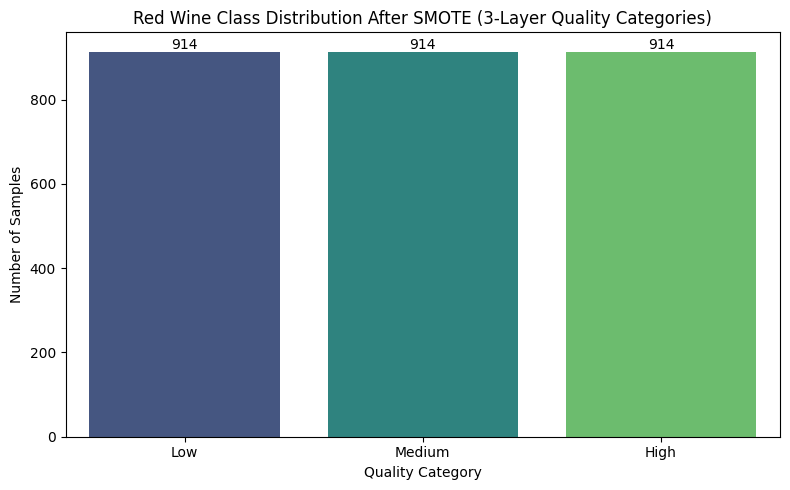

In [ ]:
# Define bins and labels for quality categorization (consistent with cell s-_e9ZKsjbM6)
bins = [2, 4, 6, 9]
labels = ['Low', 'Medium', 'High']

# Categorize y_red_train_smote into the 3 quality layers
y_red_train_smote_cat = pd.cut(y_red_train_smote, bins=bins, labels=labels, right=True, include_lowest=True)

# Get class counts for red wine
smote_red_class_counts = y_red_train_smote_cat.value_counts().reindex(labels) # Ensure order

# Create a DataFrame for plotting, using the raw quality numbers as categories
smote_red_df = pd.DataFrame({
    'Quality Category': smote_red_class_counts.index,
    'Number of Samples': smote_red_class_counts.values
})

plt.figure(figsize=(8, 5))
sns.barplot(x='Quality Category', y='Number of Samples', hue='Quality Category', data=smote_red_df, palette='viridis', legend=False)
plt.title('Red Wine Class Distribution After SMOTE (3-Layer Quality Categories)')
plt.xlabel('Quality Category')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)

# Add labels on top of the bars
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')

plt.tight_layout()
plt.show()

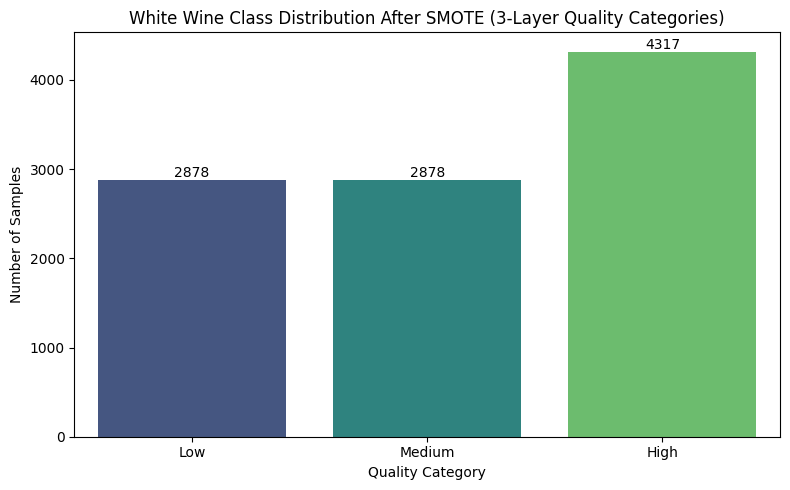

In [ ]:
# Define bins and labels for quality categorization (consistent with cell s-_e9ZKsjbM6)
bins = [2, 4, 6, 9]
labels = ['Low', 'Medium', 'High']

# Categorize y_white_train_smote into the 3 quality layers
y_white_train_smote_cat = pd.cut(y_white_train_smote, bins=bins, labels=labels, right=True, include_lowest=True)

# Get class counts for white wine
smote_white_class_counts = y_white_train_smote_cat.value_counts().reindex(labels) # Ensure order

# Create a DataFrame for plotting, using the raw quality numbers as categories
smote_white_df = pd.DataFrame({
    'Quality Category': smote_white_class_counts.index,
    'Number of Samples': smote_white_class_counts.values
})

plt.figure(figsize=(8, 5))
sns.barplot(x='Quality Category', y='Number of Samples', hue='Quality Category', data=smote_white_df, palette='viridis', legend=False)
plt.title('White Wine Class Distribution After SMOTE (3-Layer Quality Categories)')
plt.xlabel('Quality Category')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)

# Add labels on top of the bars
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')

plt.tight_layout()
plt.show()

In [ ]:
# Train RandomForestClassifier for Red Wine
rf_red_model = RandomForestClassifier(random_state=42)
rf_red_model.fit(X_red_train_smote, y_red_train_smote)

print("Red Wine RandomForestClassifier trained successfully.")

In [ ]:
# Train RandomForestClassifier for White Wine
rf_white_model = RandomForestClassifier(random_state=42)
rf_white_model.fit(X_white_train_smote, y_white_train_smote)

print("White Wine RandomForestClassifier trained successfully.")

In [ ]:
# Make predictions for Red Wine model on its test data
red_predictions = rf_red_model.predict(X_red_test)

In [ ]:
# Make predictions for White Wine model on its test data
white_predictions = rf_white_model.predict(X_white_test)

In [ ]:
# Calculate accuracy for Red Wine model
red_accuracy = accuracy_score(y_red_test, red_predictions)
print('Red Wine Model Accuracy:', red_accuracy)

In [ ]:
# Calculate accuracy for White Wine model
white_accuracy = accuracy_score(y_white_test, white_predictions)
print('White Wine Model Accuracy:', white_accuracy)

In [ ]:
from sklearn.metrics import f1_score

# Calculate and print F1 score for the Red Wine Random Forest Model
red_f1 = f1_score(y_red_test, red_predictions, average='weighted')
print('Red Wine RF Model F1 Score   : ', red_f1)

# Calculate and print F1 score for the White Wine Random Forest Model
white_f1 = f1_score(y_white_test, white_predictions, average='weighted')
print('White Wine RF Model F1 Score : ', white_f1)

In [ ]:
from xgboost import XGBClassifier

# Map original quality scores (3-8) to 0-indexed labels (0-5)
# The unique values in y_red_train_smote are likely 3, 4, 5, 6, 7, 8.
# We need to map them to 0, 1, 2, 3, 4, 5 respectively.
quality_mapping_red = {quality: i for i, quality in enumerate(sorted(y_red_train_smote.unique()))}
y_red_train_smote_mapped = y_red_train_smote.map(quality_mapping_red)

# Initialize and train the XGBoost model for Red Wine
# Set objective for multi-class classification and num_class based on the 3 new categories (0, 1, 2)
xgboost_red_model = XGBClassifier(objective='multi:softmax', num_class=len(quality_mapping_red), random_state=42, enable_categorical=False)
xgboost_red_model.fit(X_red_train_smote, y_red_train_smote_mapped)

print("XGBoost Model for Red Wine trained successfully.")

In [ ]:
# Map original quality scores (3-9) to 0-indexed labels (0-6) for white wine
# The unique values in y_white_train_smote are likely 3, 4, 5, 6, 7, 8, 9.
# We need to map them to 0, 1, 2, 3, 4, 5, 6 respectively.
quality_mapping_white = {quality: i for i, quality in enumerate(sorted(y_white_train_smote.unique()))}
y_white_train_smote_mapped = y_white_train_smote.map(quality_mapping_white)

# Initialize and train the XGBoost model for White Wine
xgboost_white_model = XGBClassifier(objective='multi:softmax', num_class=len(quality_mapping_white), random_state=42, enable_categorical=False)
xgboost_white_model.fit(X_white_train_smote, y_white_train_smote_mapped)

print("XGBoost Model for White Wine trained successfully.")

In [ ]:
# Make predictions for White Wine XGBoost model on its test data

# Before making predictions, we need to map the original quality scores (3-9)
# in y_white_test to the 0-indexed labels (0-6) that the model was trained on.
# This ensures consistency between the model's output and the true labels.
quality_mapping_white_test = {quality: i for i, quality in enumerate(sorted(y_white_test.unique()))}
y_white_test_mapped = y_white_test.map(quality_mapping_white_test)

xgboost_white_predictions = xgboost_white_model.predict(X_white_test)

print("Predictions for White Wine XGBoost model generated.")

In [ ]:
# Calculate accuracy for White Wine XGBoost model
xgboost_white_accuracy = accuracy_score(y_white_test_mapped, xgboost_white_predictions)
print('White Wine XGBoost Model Accuracy:', xgboost_white_accuracy)

In [ ]:
# Make predictions for Red Wine XGBoost model on its test data

# Before making predictions, we need to map the original quality scores (3-8)
# in y_red_test to the 0-indexed labels (0-5) that the model was trained on.
# This ensures consistency between the model's output and the true labels.
quality_mapping_red_test = {quality: i for i, quality in enumerate(sorted(y_red_test.unique()))}
y_red_test_mapped = y_red_test.map(quality_mapping_red_test)

xgboost_red_predictions = xgboost_red_model.predict(X_red_test)

print("Predictions for Red Wine XGBoost model generated.")

In [ ]:
# Calculate accuracy for Red Wine XGBoost model
xgboost_red_accuracy = accuracy_score(y_red_test_mapped, xgboost_red_predictions)
print('Red Wine XGBoost Model Accuracy:', xgboost_red_accuracy)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate classification report for Red Wine XGBoost model
print("\nClassification Report for Red Wine XGBoost Model:")
print(classification_report(y_red_test_mapped, xgboost_red_predictions))

# Generate and plot confusion matrix for Red Wine XGBoost model
cm_red = confusion_matrix(y_red_test_mapped, xgboost_red_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_red, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(quality_mapping_red_test.values()),
            yticklabels=sorted(quality_mapping_red_test.values()))
plt.title('Confusion Matrix for Red Wine XGBoost Model')
plt.xlabel('Predicted Label (0-indexed quality)')
plt.ylabel('True Label (0-indexed quality)')
plt.show()

In [ ]:
# Generate classification report for White Wine XGBoost model
print("\nClassification Report for White Wine XGBoost Model:")
print(classification_report(y_white_test_mapped, xgboost_white_predictions))

# Generate and plot confusion matrix for White Wine XGBoost model
cm_white = confusion_matrix(y_white_test_mapped, xgboost_white_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_white, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(quality_mapping_white_test.values()),
            yticklabels=sorted(quality_mapping_white_test.values()))
plt.title('Confusion Matrix for White Wine XGBoost Model')
plt.xlabel('Predicted Label (0-indexed quality)')
plt.ylabel('True Label (0-indexed quality)')
plt.show()

### SHAP Analysis for Red Wine XGBoost Model

SHAP (SHapley Additive exPlanations) is a game theory approach used to explain the output of any machine learning model. It connects optimal credit allocation with local explanations using the classic Shapley values from game theory.

Here, we will use SHAP to identify the features that contribute most to the predictions of the Red Wine XGBoost model. The summary plot below shows the overall feature importance, where features are ranked by the sum of absolute SHAP values across all samples, and the colors indicate the impact of a feature's value (e.g., high vs. low) on the prediction.


In [ ]:
import shap

# Create a SHAP TreeExplainer for the Red Wine XGBoost model
explainer_red = shap.TreeExplainer(xgboost_red_model)

# Calculate SHAP values for the Red Wine test set
# shap_values_red will be a list of arrays, one for each class (e.g., [shap_class0, shap_class1, shap_class2])
shap_values_red = explainer_red.shap_values(X_red_test)

# Generate a summary plot showing overall feature importance for Red Wine
plt.figure(figsize=(12, 7))
shap.summary_plot(shap_values_red, X_red_test, plot_type='bar', show=False)
plt.title('Overall Feature Importance for Red Wine XGBoost Model (Mean Absolute SHAP Value)')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()

print("Overall SHAP feature importance plot generated for Red Wine.")

### SHAP Analysis for White Wine XGBoost Model

Similarly, we will perform SHAP analysis for the White Wine XGBoost model to understand its feature importance. This will allow for a direct comparison of the key factors influencing quality predictions between red and white wines.


In [ ]:
# Create a SHAP TreeExplainer for the White Wine XGBoost model
explainer_white = shap.TreeExplainer(xgboost_white_model)

# Calculate SHAP values for the White Wine test set
shap_values_white = explainer_white.shap_values(X_white_test)

# Generate a summary plot showing overall feature importance for White Wine
plt.figure(figsize=(12, 7))
shap.summary_plot(shap_values_white, X_white_test, plot_type='bar', show=False)
plt.title('Overall Feature Importance for White Wine XGBoost Model (Mean Absolute SHAP Value)')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()

print("Overall SHAP feature importance plot generated for White Wine.")

### Re-applying SMOTE for 3-Layer Quality Categorization and New Model Training

As requested, we will now re-process the training data to apply SMOTE directly to the 3-layer quality categories ('Low', 'Medium', 'High'). This ensures that the models trained subsequently will have a balanced representation of these broad quality levels.

First, we'll create the 3-layer categorical targets for the training sets, then apply SMOTE, and finally train and evaluate new RandomForest and XGBoost models based on this balanced 3-layer classification objective.

In [ ]:
# Define bins and labels for the 3-layer quality categorization (consistent with previous definitions)
bins = [2, 4, 6, 9] # Low: 3-4, Medium: 5-6, High: 7-8-9
labels = ['Low', 'Medium', 'High'] # Will be mapped to 0, 1, 2 by .cat.codes

# Convert y_red_train to 3-layer categorical targets (0, 1, 2)
y_red_train_3cat = pd.cut(y_red_train, bins=bins, labels=labels, right=True, include_lowest=True).cat.codes.astype(int)

# Convert y_white_train to 3-layer categorical targets (0, 1, 2)
y_white_train_3cat = pd.cut(y_white_train, bins=bins, labels=labels, right=True, include_lowest=True).cat.codes.astype(int)

print("Red Wine training quality categorized into 3 layers.")
print("White Wine training quality categorized into 3 layers.")

In [ ]:
smote = SMOTE(random_state=42, k_neighbors=3)

# Apply SMOTE for Red Wine using the 3-layer categories
X_red_train_smote_3cat, y_red_train_smote_3cat = smote.fit_resample(
     X_red_train,
     y_red_train_3cat
)

print("Red Wine training data reshaped with SMOTE for 3-layer categories.")
print(f"X_red_train_smote_3cat shape: {X_red_train_smote_3cat.shape}")
print(f"y_red_train_smote_3cat shape: {y_red_train_smote_3cat.shape}")

# Apply SMOTE for White Wine using the 3-layer categories
X_white_train_smote_3cat, y_white_train_smote_3cat = smote.fit_resample(
     X_white_train,
     y_white_train_3cat
)

print("\nWhite Wine training data reshaped with SMOTE for 3-layer categories.")
print(f"X_white_train_smote_3cat shape: {X_white_train_smote_3cat.shape}")
print(f"y_white_train_smote_3cat shape: {y_white_train_smote_3cat.shape}")

#### Visualize Class Distribution After 3-Layer SMOTE

Let's verify that the 3-layer quality categories are now balanced after applying SMOTE.

In [ ]:
# Get class counts for red wine after 3-layer SMOTE
smote_red_3cat_counts = pd.Series(y_red_train_smote_3cat).value_counts().sort_index()

smote_red_3cat_df = pd.DataFrame({
    'Quality Category': ['Low', 'Medium', 'High'], # Map 0, 1, 2 back to labels for plotting
    'Number of Samples': smote_red_3cat_counts.values
})

plt.figure(figsize=(8, 5))
sns.barplot(x='Quality Category', y='Number of Samples', hue='Quality Category', data=smote_red_3cat_df, palette='viridis', legend=False)
plt.title('Red Wine Class Distribution After 3-Layer SMOTE')
plt.xlabel('Quality Category')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')
plt.tight_layout()
plt.show()

# Get class counts for white wine after 3-layer SMOTE
smote_white_3cat_counts = pd.Series(y_white_train_smote_3cat).value_counts().sort_index()

smote_white_3cat_df = pd.DataFrame({
    'Quality Category': ['Low', 'Medium', 'High'],
    'Number of Samples': smote_white_3cat_counts.values
})

plt.figure(figsize=(8, 5))
sns.barplot(x='Quality Category', y='Number of Samples', hue='Quality Category', data=smote_white_3cat_df, palette='viridis', legend=False)
plt.title('White Wine Class Distribution After 3-Layer SMOTE')
plt.xlabel('Quality Category')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')
plt.tight_layout()
plt.show()

### Train and Evaluate New Models for 3-Layer Classification

Now we will train new RandomForest and XGBoost models using the SMOTEd datasets where the target variable is the 3-layer quality category. We will also adapt the test sets to these 3-layer categories for evaluation.

In [ ]:
# Convert y_red_test to 3-layer categorical targets for evaluation
y_red_test_3cat = pd.cut(y_red_test, bins=bins, labels=labels, right=True, include_lowest=True).cat.codes.astype(int)

# Train RandomForestClassifier for Red Wine (3-layer)
rf_red_model_3cat = RandomForestClassifier(random_state=42)
rf_red_model_3cat.fit(X_red_train_smote_3cat, y_red_train_smote_3cat)

# Make predictions
rf_red_predictions_3cat = rf_red_model_3cat.predict(X_red_test)

# Calculate accuracy
rf_red_accuracy_3cat = accuracy_score(y_red_test_3cat, rf_red_predictions_3cat)
print('Red Wine RandomForest (3-layer) Accuracy:', rf_red_accuracy_3cat)

# Generate classification report
print('\nRed Wine RandomForest (3-layer) Classification Report:')
print(classification_report(y_red_test_3cat, rf_red_predictions_3cat, target_names=labels))

# Generate confusion matrix
cm_rf_red_3cat = confusion_matrix(y_red_test_3cat, rf_red_predictions_3cat)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf_red_3cat, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix for Red Wine RandomForest (3-layer)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
# Convert y_white_test to 3-layer categorical targets for evaluation
y_white_test_3cat = pd.cut(y_white_test, bins=bins, labels=labels, right=True, include_lowest=True).cat.codes.astype(int)

# Train RandomForestClassifier for White Wine (3-layer)
rf_white_model_3cat = RandomForestClassifier(random_state=42)
rf_white_model_3cat.fit(X_white_train_smote_3cat, y_white_train_smote_3cat)

# Make predictions
rf_white_predictions_3cat = rf_white_model_3cat.predict(X_white_test)

# Calculate accuracy
rf_white_accuracy_3cat = accuracy_score(y_white_test_3cat, rf_white_predictions_3cat)
print('White Wine RandomForest (3-layer) Accuracy:', rf_white_accuracy_3cat)

# Generate classification report
print('\nWhite Wine RandomForest (3-layer) Classification Report:')
print(classification_report(y_white_test_3cat, rf_white_predictions_3cat, target_names=labels))

# Generate confusion matrix
cm_rf_white_3cat = confusion_matrix(y_white_test_3cat, rf_white_predictions_3cat)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf_white_3cat, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix for White Wine RandomForest (3-layer)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
from xgboost import XGBClassifier

# Train XGBoostClassifier for Red Wine (3-layer)
# num_class is 3 for 'Low', 'Medium', 'High'
xgboost_red_model_3cat = XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, enable_categorical=False)
xgboost_red_model_3cat.fit(X_red_train_smote_3cat, y_red_train_smote_3cat)

# Make predictions
xgboost_red_predictions_3cat = xgboost_red_model_3cat.predict(X_red_test)

# Calculate accuracy
xgboost_red_accuracy_3cat = accuracy_score(y_red_test_3cat, xgboost_red_predictions_3cat)
print('Red Wine XGBoost (3-layer) Accuracy:', xgboost_red_accuracy_3cat)

# Generate classification report
print('\nRed Wine XGBoost (3-layer) Classification Report:')
print(classification_report(y_red_test_3cat, xgboost_red_predictions_3cat, target_names=labels))

# Generate confusion matrix
cm_xgboost_red_3cat = confusion_matrix(y_red_test_3cat, xgboost_red_predictions_3cat)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_xgboost_red_3cat, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix for Red Wine XGBoost (3-layer)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
# Train XGBoostClassifier for White Wine (3-layer)
# num_class is 3 for 'Low', 'Medium', 'High'
xgboost_white_model_3cat = XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, enable_categorical=False)
xgboost_white_model_3cat.fit(X_white_train_smote_3cat, y_white_train_smote_3cat)

# Make predictions
xgboost_white_predictions_3cat = xgboost_white_model_3cat.predict(X_white_test)

# Calculate accuracy
xgboost_white_accuracy_3cat = accuracy_score(y_white_test_3cat, xgboost_white_predictions_3cat)
print('White Wine XGBoost (3-layer) Accuracy:', xgboost_white_accuracy_3cat)

# Generate classification report
print('\nWhite Wine XGBoost (3-layer) Classification Report:')
print(classification_report(y_white_test_3cat, xgboost_white_predictions_3cat, target_names=labels))

# Generate confusion matrix
cm_xgboost_white_3cat = confusion_matrix(y_white_test_3cat, xgboost_white_predictions_3cat)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_xgboost_white_3cat, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix for White Wine XGBoost (3-layer)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score

# Make predictions and evaluate the Red Wine 3-layer XGBoost Model
xgboost_red_predictions_3cat = xgboost_red_model_3cat.predict(X_red_test)
xgboost_red_accuracy_3cat = accuracy_score(y_red_test_3cat, xgboost_red_predictions_3cat)
print('Red Wine XGBoost Model (3-layer) Accuracy  :', xgboost_red_accuracy_3cat)

# Make predictions and evaluate the White Wine 3-layer XGBoost Model
xgboost_white_predictions_3cat = xgboost_white_model_3cat.predict(X_white_test)
xgboost_white_accuracy_3cat = accuracy_score(y_white_test_3cat, xgboost_white_predictions_3cat)
print('White Wine XGBoost Model (3-layer) Accuracy:', xgboost_white_accuracy_3cat)

In [ ]:
# Calculate and print F1 Score for Red and White Wine 3-layer XGBoost Models
from sklearn.metrics import f1_score

# Red Wine F1 Score
xgboost_red_f1_3cat = f1_score(y_red_test_3cat, xgboost_red_predictions_3cat, average='weighted')
print('Red Wine XGBoost Model (3-layer) F1 Score  :', xgboost_red_f1_3cat)

# White Wine F1 Score
xgboost_white_f1_3cat = f1_score(y_white_test_3cat, xgboost_white_predictions_3cat, average='weighted')
print('White Wine XGBoost Model (3-layer) F1 Score:', xgboost_white_f1_3cat)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Load datasets and drop duplicates
path = '/content/sample_data'
red = pd.read_csv(path + '/winequality-red.csv', sep=';')
white = pd.read_csv(path + '/winequality-white.csv', sep=';')

red = red.drop_duplicates()
white = white.drop_duplicates()

# 2. Extract features and targets
X_red = red.drop(["quality"], axis=1, errors='ignore')
y_red = red["quality"]

X_white = white.drop(["quality"], axis=1, errors='ignore')
y_white = white["quality"]

# 3. Scale features
scaler = MinMaxScaler()
X_red_scaled = pd.DataFrame(scaler.fit_transform(X_red), columns=X_red.columns)
X_white_scaled = pd.DataFrame(scaler.fit_transform(X_white), columns=X_white.columns)

# 4. Train-Test Split
X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(
    X_red_scaled, y_red, test_size=0.2, random_state=42
)
X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(
    X_white_scaled, y_white, test_size=0.2, random_state=42
)

# 5. Bin into 3 categories (Low, Medium, High)
bins = [2, 4, 6, 9]
labels = ['Low', 'Medium', 'High']

y_red_train_3cat = pd.cut(y_red_train, bins=bins, labels=labels, right=True, include_lowest=True).cat.codes.astype(int)
y_white_train_3cat = pd.cut(y_white_train, bins=bins, labels=labels, right=True, include_lowest=True).cat.codes.astype(int)
y_red_test_3cat = pd.cut(y_red_test, bins=bins, labels=labels, right=True, include_lowest=True).cat.codes.astype(int)
y_white_test_3cat = pd.cut(y_white_test, bins=bins, labels=labels, right=True, include_lowest=True).cat.codes.astype(int)

# 6. Apply SMOTE
smote = SMOTE(random_state=42, k_neighbors=3)
X_red_train_smote_3cat, y_red_train_smote_3cat = smote.fit_resample(X_red_train, y_red_train_3cat)
X_white_train_smote_3cat, y_white_train_smote_3cat = smote.fit_resample(X_white_train, y_white_train_3cat)

### SVM for Red Wine ###
print("--- Training SVM for Red Wine (3-layer) ---")
svm_red = SVC(kernel='rbf', random_state=42)
svm_red.fit(X_red_train_smote_3cat, y_red_train_smote_3cat)

svm_red_preds = svm_red.predict(X_red_test)
svm_red_acc = accuracy_score(y_red_test_3cat, svm_red_preds)
print(f"Red Wine SVM Accuracy: {svm_red_acc:.4f}")
print("\nRed Wine SVM Classification Report:")
print(classification_report(y_red_test_3cat, svm_red_preds, target_names=labels))

### SVM for White Wine ###
print("\n--- Training SVM for White Wine (3-layer) ---")
svm_white = SVC(kernel='rbf', random_state=42)
svm_white.fit(X_white_train_smote_3cat, y_white_train_smote_3cat)

svm_white_preds = svm_white.predict(X_white_test)
svm_white_acc = accuracy_score(y_white_test_3cat, svm_white_preds)
print(f"White Wine SVM Accuracy: {svm_white_acc:.4f}")
print("\nWhite Wine SVM Classification Report:")
print(classification_report(y_white_test_3cat, svm_white_preds, target_names=labels))

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# Define the labels for the 3-layer categorization, consistent with previous cells
labels = ['Low', 'Medium', 'High']

### SHAP Analysis for Red Wine RandomForest (3-layer) Model ###
print("\n--- SHAP Analysis for Red Wine RandomForest (3-layer) Model ---")

# Create a SHAP TreeExplainer for the Red Wine RandomForest model (3-layer)
explainer_rf_red_3cat = shap.TreeExplainer(rf_red_model_3cat)

# Calculate SHAP values for the Red Wine test set (3-layer)
shap_values_rf_red_3cat = explainer_rf_red_3cat.shap_values(X_red_test)

# Generate a summary plot showing overall feature importance for Red Wine
plt.figure(figsize=(12, 7))
shap.summary_plot(shap_values_rf_red_3cat, X_red_test, plot_type='bar', show=False, class_names=labels)
plt.title('Overall Feature Importance for Red Wine RandomForest (3-layer) Model')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()

print("Overall SHAP feature importance plot generated for Red Wine RandomForest.")

### SHAP Analysis for White Wine RandomForest (3-layer) Model ###
print("\n--- SHAP Analysis for White Wine RandomForest (3-layer) Model ---")

# Create a SHAP TreeExplainer for the White Wine RandomForest model (3-layer)
explainer_rf_white_3cat = shap.TreeExplainer(rf_white_model_3cat)

# Calculate SHAP values for the White Wine test set (3-layer)
shap_values_rf_white_3cat = explainer_rf_white_3cat.shap_values(X_white_test)

# Generate a summary plot showing overall feature importance for White Wine
plt.figure(figsize=(12, 7))
shap.summary_plot(shap_values_rf_white_3cat, X_white_test, plot_type='bar', show=False, class_names=labels)
plt.title('Overall Feature Importance for White Wine RandomForest (3-layer) Model')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()

print("Overall SHAP feature importance plot generated for White Wine RandomForest.")


In [ ]:
from sklearn.metrics import classification_report

labels = ['Low', 'Medium', 'High']

print("--- SVM Red Wine (3-layer) Classification Report ---")
print(classification_report(y_red_test_3cat, svm_red_preds, target_names=labels))

print("\n--- SVM White Wine (3-layer) Classification Report ---")
print(classification_report(y_white_test_3cat, svm_white_preds, target_names=labels))

In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE


# ============================================================
# 2. LOAD DATA
# ============================================================

path = '/content/sample_data'

red_df = pd.read_csv(
    path + '/winequality-red.csv',
    sep=';'
).drop_duplicates()

white_df = pd.read_csv(
    path + '/winequality-white.csv',
    sep=';'
).drop_duplicates()


# ============================================================
# 3. CREATE 3 WINE QUALITY CLASSES
# ============================================================
#
# Low    = quality <= 4
# Medium = quality 5-6
# High   = quality >= 7
#
# 0 = Low
# 1 = Medium
# 2 = High
# ============================================================

def create_target(df):
    y = df["quality"]
    bins = [-np.inf, 4, 6, np.inf]
    labels = ['Low', 'Medium', 'High']
    y_3cat = pd.cut(
        y,
        bins=bins,
        labels=labels
    )
    # Convert:
    # Low    -> 0
    # Medium -> 1
    # High   -> 2
    y_3cat = y_3cat.cat.codes
    return y_3cat


# ============================================================
# 4. PREPARE X AND y
# ============================================================

def prepare_data(df):
    X = df.drop(
        columns=["quality"],
        errors="ignore"
    ).copy()
    y = create_target(df)
    return X, y

X_red, y_red = prepare_data(red_df)
X_white, y_white = prepare_data(white_df)


# ============================================================
# 5. TRAIN / TEST SPLIT WITH STRATIFY TO PREVENT DATA LEAKAGE
# ============================================================

X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(
    X_red,
    y_red,
    test_size=0.2,
    random_state=42,
    stratify=y_red
)

X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(
    X_white,
    y_white,
    test_size=0.2,
    random_state=42,
    stratify=y_white
)


# ============================================================
# 6. CREATE MODELS WITH SMOTE AND MINMAXSCALER IN PIPELINE
# ============================================================
#
# SMOTE:
#   Applied inside Pipeline (Only on Train folds during CV)
#
# Scaling:
#   MinMaxScaler is applied inside the Pipeline for ALL models
#   to scale features into [0, 1] range consistently without leakage.
#
# ============================================================

def create_models():
    models = {
        "Random Forest": Pipeline([
            (
                "smote",
                SMOTE(
                    random_state=42,
                    k_neighbors=3
                )
            ),
            (
                "scaler",
                MinMaxScaler()
            ),
            (
                "model",
                RandomForestClassifier(
                    random_state=42,
                    n_estimators=100
                )
            )
        ]),

        "XGBoost": Pipeline([
            (
                "smote",
                SMOTE(
                    random_state=42,
                    k_neighbors=3
                )
            ),
            (
                "scaler",
                MinMaxScaler()
            ),
            (
                "model",
                XGBClassifier(
                    objective="multi:softmax",
                    num_class=3,
                    random_state=42,
                    enable_categorical=False
                )
            )
        ]),

        "SVM": Pipeline([
            (
                "smote",
                SMOTE(
                    random_state=42,
                    k_neighbors=3
                )
            ),
            (
                "scaler",
                MinMaxScaler()
            ),
            (
                "model",
                SVC(
                    kernel="rbf",
                    probability=True,
                    random_state=42
                )
            )
        ])
    }
    return models


# ============================================================
# 7. CROSS-VALIDATION CONFIGURATION
# ============================================================
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro"
}


# ============================================================
# 8. RUN CROSS-VALIDATION
# ============================================================

def run_cross_validation(X_train, y_train, label):
    print("\n")
    print("=" * 70)
    print(f"5-FOLD CROSS-VALIDATION: {label.upper()} WINE")
    print("=" * 70)
    models = create_models()
    cv_results = {}
    for name, pipeline in models.items():
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )
        cv_results[name] = {
            "Accuracy": scores["test_accuracy"].mean(),
            "Macro F1": scores["test_f1_macro"].mean(),
            "Weighted F1": scores["test_f1_weighted"].mean(),
            "Macro Precision": scores["test_precision_macro"].mean(),
            "Macro Recall": scores["test_recall_macro"].mean()
        }
        print(f"\n{name}")
        print(f"  Accuracy       : {cv_results[name]['Accuracy']:.4f}")
        print(f"  Macro F1       : {cv_results[name]['Macro F1']:.4f}")
        print(f"  Weighted F1    : {cv_results[name]['Weighted F1']:.4f}")
        print(f"  Macro Precision: {cv_results[name]['Macro Precision']:.4f}")
        print(f"  Macro Recall   : {cv_results[name]['Macro Recall']:.4f}")

    results_df = pd.DataFrame(cv_results).T
    print("\n")
    print("CROSS-VALIDATION SUMMARY")
    display(results_df.round(4))

    # Select svm model
    choose_model_name = "SVM"
    return models, results_df, choose_model_name


# ============================================================
# 9. TRAIN + TEST BEST MODEL
# ============================================================

def evaluate_best_model(
    models,
    choose_model_name,
    X_train,
    y_train,
    X_test,
    y_test,
    label
):
    print("\n")
    print("=" * 70)
    print(f"FINAL TEST EVALUATION: {label.upper()} WINE")
    print("=" * 70)
    best_pipeline = models[choose_model_name]

    # Train pipeline
    best_pipeline.fit(X_train, y_train)
    predictions = best_pipeline.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")
    weighted_f1 = f1_score(y_test, predictions, average="weighted")

    print(f"\nModel: {choose_model_name}")
    print(f"Accuracy    : {accuracy:.4f}")
    print(f"Macro F1    : {macro_f1:.4f}")
    print(f"Weighted F1 : {weighted_f1:.4f}")
    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Low", "Medium", "High"]
        )
    )

    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"]
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {choose_model_name} - {label} Wine")
    plt.tight_layout()
    plt.show()

    return best_pipeline, predictions


# ============================================================
# 10. SHAP ANALYSIS
# ============================================================

def run_shap(pipeline, X_test, label, model_name):
    print("\n")
    print("=" * 70)
    print(f"SHAP ANALYSIS: {label.upper()} WINE")
    print("=" * 70)
    model = pipeline.named_steps["model"]
    scaler = pipeline.named_steps["scaler"]

    # For SHAP explanation, we need scaling to be pre-applied to the background/test sample
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

    if model_name in ["XGBoost", "Random Forest"]:
        print(f"Using TreeExplainer for {model_name}")
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_test_scaled)
        plt.figure(figsize=(10, 6))
        shap.summary_plot(
            shap_values,
            X_test_scaled,
            class_names=["Low", "Medium", "High"],
            show=False
        )
        plt.title(f"SHAP Feature Importance - {model_name} - {label} Wine")
        plt.tight_layout()
        plt.show()

    elif model_name == "SVM":
        print("Using KernelExplainer for SVM")
        # Reduce size of background data for KernelExplainer efficiency
        X_background = X_test_scaled.sample(min(50, len(X_test_scaled)), random_state=42)
        X_explain = X_test_scaled.sample(min(100, len(X_test_scaled)), random_state=42)

        explainer = shap.KernelExplainer(
            model.predict_proba,
            X_background
        )
        shap_values = explainer.shap_values(X_explain)
        plt.figure(figsize=(10, 6))
        shap.summary_plot(
            shap_values,
            X_explain,
            class_names=["Low", "Medium", "High"],
            show=False
        )
        plt.title(f"SHAP Feature Importance - SVM - {label} Wine")
        plt.tight_layout()
        plt.show()


# ============================================================
# 11. RUN RED WINE EXPERIMENTS
# ============================================================

red_models, red_cv_results, red_best_model = run_cross_validation(
    X_red_train,
    y_red_train,
    "Red"
)
red_best_pipeline, red_predictions = evaluate_best_model(
    red_models,
    red_best_model,
    X_red_train,
    y_red_train,
    X_red_test,
    y_red_test,
    "Red"
)
run_shap(
    red_best_pipeline,
    X_red_test,
    "Red",
    red_best_model
)


# ============================================================
# 12. RUN WHITE WINE EXPERIMENTS
# ============================================================

white_models, white_cv_results, white_best_model = run_cross_validation(
    X_white_train,
    y_white_train,
    "White"
)
white_best_pipeline, white_predictions = evaluate_best_model(
    white_models,
    white_best_model,
    X_white_train,
    y_white_train,
    X_white_test,
    y_white_test,
    "White"
)
run_shap(
    white_best_pipeline,
    X_white_test,
    "White",
    white_best_model
)

In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE


In [ ]:

# ============================================================
# 2. LOAD DATA
# ============================================================

path = '/content/sample_data'

red_df = pd.read_csv(
    path + '/winequality-red.csv',
    sep=';'
).drop_duplicates()

white_df = pd.read_csv(
    path + '/winequality-white.csv',
    sep=';'
).drop_duplicates()

In [ ]:

# ============================================================
# 3. CREATE 3 WINE QUALITY CLASSES
# ============================================================

# Low    = quality <= 4
# Medium = quality 5-6
# High   = quality >= 7

# 0 = Low
# 1 = Medium
# 2 = High
# ============================================================

def create_target(df):
    y = df["quality"]
    bins = [-np.inf, 4, 6, np.inf]
    labels = ['Low', 'Medium', 'High']

    y_3cat = pd.cut(
        y,
        bins=bins,
        labels=labels
    )

    # Convert:
    # Low    -> 0
    # Medium -> 1
    # High   -> 2
    y_3cat = y_3cat.cat.codes

    return y_3cat

In [ ]:

# ============================================================
# 4. PREPARE X AND y
# ============================================================

def prepare_data(df):
    X = df.drop(
        columns=["quality"],
        errors="ignore"
    ).copy()

    y = create_target(df)

    return X, y


X_red, y_red = prepare_data(red_df)
X_white, y_white = prepare_data(white_df)

In [ ]:

# ============================================================
# 5. TRAIN / TEST SPLIT WITH STRATIFY TO PREVENT DATA LEAKAGE
# ============================================================

X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(
    X_red,
    y_red,
    test_size=0.2,
    random_state=42,
    stratify=y_red
)

X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(
    X_white,
    y_white,
    test_size=0.2,
    random_state=42,
    stratify=y_white
)

In [ ]:

# ============================================================
# 6. CREATE MODELS WITH SMOTE AND MINMAXSCALER IN PIPELINE
# ============================================================

# SMOTE:
#   Applied inside Pipeline (Only on Train folds during CV)

# Scaling:
#   MinMaxScaler is applied inside the Pipeline for ALL models
#   to scale features into [0, 1] range consistently without leakage.

# ============================================================

def create_models():
    models = {
        "Random Forest": Pipeline([
            (
                "smote",
                SMOTE(
                    random_state=42,
                    k_neighbors=3
                )
            ),
            (
                "scaler",
                MinMaxScaler()
            ),
            (
                "model",
                RandomForestClassifier(
                    random_state=42,
                    n_estimators=100
                )
            )
        ]),

        "XGBoost": Pipeline([
            (
                "smote",
                SMOTE(
                    random_state=42,
                    k_neighbors=3
                )
            ),
            (
                "scaler",
                MinMaxScaler()
            ),
            (
                "model",
                XGBClassifier(
                    objective="multi:softmax",
                    num_class=3,
                    random_state=42,
                    enable_categorical=False
                )
            )
        ]),

        "SVM": Pipeline([
            (
                "smote",
                SMOTE(
                    random_state=42,
                    k_neighbors=3
                )
            ),
            (
                "scaler",
                MinMaxScaler()
            ),
            (
                "model",
                SVC(
                    kernel="rbf",
                    probability=True,
                    random_state=42
                )
            )
        ])
    }

    return models

In [ ]:

# ============================================================
# 7. CROSS-VALIDATION CONFIGURATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro"
}

In [ ]:

# ============================================================
# 8. RUN CROSS-VALIDATION
# ============================================================

def run_cross_validation(X_train, y_train, label):
    print("\n")
    print("=" * 70)
    print(f"5-FOLD CROSS-VALIDATION: {label.upper()} WINE")
    print("=" * 70)

    models = create_models()
    cv_results = {}

    for name, pipeline in models.items():
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )

        cv_results[name] = {
            "Accuracy": scores["test_accuracy"].mean(),
            "Macro F1": scores["test_f1_macro"].mean(),
            "Weighted F1": scores["test_f1_weighted"].mean(),
            "Macro Precision": scores["test_precision_macro"].mean(),
            "Macro Recall": scores["test_recall_macro"].mean()
        }

        print(f"\n{name}")
        print(f"  Accuracy       : {cv_results[name]['Accuracy']:.4f}")
        print(f"  Macro F1       : {cv_results[name]['Macro F1']:.4f}")
        print(f"  Weighted F1    : {cv_results[name]['Weighted F1']:.4f}")
        print(f"  Macro Precision: {cv_results[name]['Macro Precision']:.4f}")
        print(f"  Macro Recall   : {cv_results[name]['Macro Recall']:.4f}")

    results_df = pd.DataFrame(cv_results).T

    print("\n")
    print("CROSS-VALIDATION SUMMARY")
    display(results_df.round(4))

    # Select svm model
    choose_model_name = "SVM"

    return models, results_df, choose_model_name

In [ ]:

# ============================================================
# 9. TRAIN + TEST BEST MODEL
# ============================================================

def evaluate_best_model(
    models,
    choose_model_name,
    X_train,
    y_train,
    X_test,
    y_test,
    label
):
    print("\n")
    print("=" * 70)
    print(f"FINAL TEST EVALUATION: {label.upper()} WINE")
    print("=" * 70)

    best_pipeline = models[choose_model_name]

    # Train pipeline
    best_pipeline.fit(X_train, y_train)
    predictions = best_pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")
    weighted_f1 = f1_score(y_test, predictions, average="weighted")

    print(f"\nModel: {choose_model_name}")
    print(f"Accuracy    : {accuracy:.4f}")
    print(f"Macro F1    : {macro_f1:.4f}")
    print(f"Weighted F1 : {weighted_f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Low", "Medium", "High"]
        )
    )

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {choose_model_name} - {label} Wine")
    plt.tight_layout()
    plt.show()

    return best_pipeline, predictions

In [ ]:

# ============================================================
# 10. SHAP ANALYSIS
# ============================================================

def run_shap(pipeline, X_test, label, model_name):
    print("\n")
    print("=" * 70)
    print(f"SHAP ANALYSIS: {label.upper()} WINE")
    print("=" * 70)

    model = pipeline.named_steps["model"]
    scaler = pipeline.named_steps["scaler"]

    # For SHAP explanation, we need scaling to be pre-applied to the background/test sample
    X_test_scaled = pd.DataFrame(
        scaler.transform(X_test),
        columns=X_test.columns
    )

    if model_name in ["XGBoost", "Random Forest"]:
        print(f"Using TreeExplainer for {model_name}")

        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_test_scaled)

        plt.figure(figsize=(10, 6))
        shap.summary_plot(
            shap_values,
            X_test_scaled,
            class_names=["Low", "Medium", "High"],
            show=False
        )

        plt.title(f"SHAP Feature Importance - {model_name} - {label} Wine")
        plt.tight_layout()
        plt.show()

    elif model_name == "SVM":
        print("Using KernelExplainer for SVM")

        # Reduce size of background data for KernelExplainer efficiency
        X_background = X_test_scaled.sample(
            min(50, len(X_test_scaled)),
            random_state=42
        )

        X_explain = X_test_scaled.sample(
            min(100, len(X_test_scaled)),
            random_state=42
        )

        explainer = shap.KernelExplainer(
            model.predict_proba,
            X_background
        )

        shap_values = explainer.shap_values(X_explain)

        plt.figure(figsize=(10, 6))
        shap.summary_plot(
            shap_values,
            X_explain,
            class_names=["Low", "Medium", "High"],
            show=False
        )

        plt.title(f"SHAP Feature Importance - SVM - {label} Wine")
        plt.tight_layout()
        plt.show()

In [ ]:
# ============================================================
# 11. RUN RED WINE EXPERIMENTS
# ============================================================

red_models, red_cv_results, red_best_model = run_cross_validation(
    X_red_train,
    y_red_train,
    "Red"
)

red_best_pipeline, red_predictions = evaluate_best_model(
    red_models,
    red_best_model,
    X_red_train,
    y_red_train,
    X_red_test,
    y_red_test,
    "Red"
)

run_shap(
    red_best_pipeline,
    X_red_test,
    "Red",
    red_best_model
)

In [ ]:

# ============================================================
# 12. RUN WHITE WINE EXPERIMENTS
# ============================================================

white_models, white_cv_results, white_best_model = run_cross_validation(
    X_white_train,
    y_white_train,
    "White"
)

white_best_pipeline, white_predictions = evaluate_best_model(
    white_models,
    white_best_model,
    X_white_train,
    y_white_train,
    X_white_test,
    y_white_test,
    "White"
)

run_shap(
    white_best_pipeline,
    X_white_test,
    "White",
    white_best_model
)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# 1. Load datasets and drop duplicates
path = '/content/sample_data'
red_df = pd.read_csv(path + '/winequality-red.csv', sep=';').drop_duplicates()
white_df = pd.read_csv(path + '/winequality-white.csv', sep=';').drop_duplicates()

# 2. Extract features and continuous regression targets (using original quality scores)
X_red = red_df.drop(columns=['quality'], errors='ignore')
y_red_reg = red_df['quality']

X_white = white_df.drop(columns=['quality'], errors='ignore')
y_white_reg = white_df['quality']

# 3. Train-Test Split (80/20)
X_red_train, X_red_test, y_red_reg_train, y_red_reg_test = train_test_split(
    X_red, y_red_reg, test_size=0.2, random_state=42
)
X_white_train, X_white_test, y_white_reg_train, y_white_reg_test = train_test_split(
    X_white, y_white_reg, test_size=0.2, random_state=42
)

# 4. Initialize scale transformers to ensure features are normalized
scaler_red = MinMaxScaler()
X_red_train_scaled = scaler_red.fit_transform(X_red_train)
X_red_test_scaled = scaler_red.transform(X_red_test)

scaler_white = MinMaxScaler()
X_white_train_scaled = scaler_white.fit_transform(X_white_train)
X_white_test_scaled = scaler_white.transform(X_white_test)

# --- 5. Linear Regression for Red Wine ---
print("=== LINEAR REGRESSION: RED WINE ===")
lr_red = LinearRegression()
lr_red.fit(X_red_train_scaled, y_red_reg_train)

red_reg_preds = lr_red.predict(X_red_test_scaled)
print(f"Red Wine MSE: {mean_squared_error(y_red_reg_test, red_reg_preds):.4f}")
print(f"Red Wine R2:  {r2_score(y_red_reg_test, red_reg_preds):.4f}")

# --- 6. Linear Regression for White Wine ---
print("\n=== LINEAR REGRESSION: WHITE WINE ===")
lr_white = LinearRegression()
lr_white.fit(X_white_train_scaled, y_white_reg_train)

white_reg_preds = lr_white.predict(X_white_test_scaled)
print(f"White Wine MSE: {mean_squared_error(y_white_reg_test, white_reg_preds):.4f}")
print(f"White Wine R2:  {r2_score(y_white_reg_test, white_reg_preds):.4f}")

# --- 7. Coefficients Comparison ---
coeff_df = pd.DataFrame({
    'Feature': X_red_train.columns,
    'Red Wine Coeff': lr_red.coef_,
    'White Wine Coeff': lr_white.coef_
})
print("\n=== MODEL COEFFICIENTS COMPARISON ===")
display(coeff_df.round(4))

In [ ]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
from imblearn.over_sampling import SMOTE

# --- 1. SETUP & PREPROCESSING ---
path = '/content/sample_data'
red_df = pd.read_csv(path + '/winequality-red.csv', sep=';').drop_duplicates()
white_df = pd.read_csv(path + '/winequality-white.csv', sep=';').drop_duplicates()

def preprocess_wine_data(df):
    X = df.drop(["quality"], axis=1, errors='ignore')
    y = df["quality"]
    scaler = MinMaxScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
    bins = [2, 4, 6, 9]
    labels = ['Low', 'Medium', 'High']
    y_3cat = pd.cut(y, bins=bins, labels=labels, right=True, include_lowest=True).cat.codes.astype(int)
    return X_scaled, y_3cat

X_red, y_red = preprocess_wine_data(red_df)
X_white, y_white = preprocess_wine_data(white_df)

# Train-Test Split (80/20)
X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(X_red, y_red, test_size=0.2, random_state=42, stratify=y_red)
X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(X_white, y_white, test_size=0.2, random_state=42, stratify=y_white)

# --- 2. PIPELINE EXECUTION FUNCTION ---
def run_pipeline(X_train, X_test, y_train, y_test, label):
    print(f"\n=======================================================")
    print(f"      RUNNING PIPELINE FOR: {label.upper()} WINE")
    print(f"=======================================================")

    # Initialize models
    models_original = {
        'Random Forest': RandomForestClassifier(random_state=42),
        'XGBoost': XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, enable_categorical=False),
        'SVM': SVC(kernel='rbf', random_state=42, probability=True)
    }

    # -----------------------------------------------------------------
    # BRANCH 1: Original Training Data (Non-SMOTE Baseline)
    # -----------------------------------------------------------------
    print(f"\n>>> [Branch 1] Training on Original Data (No SMOTE)... ")
    results_original = {}
    for name, model in models_original.items():
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        acc = accuracy_score(y_test, preds)
        f1 = f1_score(y_test, preds, average='weighted')
        results_original[name] = {'Accuracy': acc, 'F1': f1}
        print(f"  - {name:<15} | Test Acc: {acc:.4f} | Weighted F1: {f1:.4f}")

    # -----------------------------------------------------------------
    # BRANCH 2: SMOTE Training Data (Only applied on Train)
    # -----------------------------------------------------------------
    print(f"\n>>> [Branch 2] Training on SMOTEd Data... ")
    smote = SMOTE(random_state=42, k_neighbors=3)
    X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

    models_smote = {
        'Random Forest': RandomForestClassifier(random_state=42),
        'XGBoost': XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, enable_categorical=False),
        'SVM': SVC(kernel='rbf', random_state=42, probability=True)
    }

    results_smote = {}
    for name, model in models_smote.items():
        model.fit(X_train_smote, y_train_smote)
        preds = model.predict(X_test)
        acc = accuracy_score(y_test, preds)
        f1 = f1_score(y_test, preds, average='weighted')
        results_smote[name] = {'Accuracy': acc, 'F1': f1}
        print(f"  - {name:<15} | Test Acc: {acc:.4f} | Weighted F1: {f1:.4f}")

    # -----------------------------------------------------------------
    # BRANCH 3: SHAP Interpretation on Non-SMOTE SVM
    # -----------------------------------------------------------------
    print(f"\n>>> [Branch 3] Generating SHAP explanations on Non-SMOTE SVM model...")
    svm_model = models_original['SVM']

    # Summarize training dataset using K-means for computational efficiency
    background = shap.kmeans(X_train, 15)
    explainer = shap.KernelExplainer(svm_model.predict_proba, background)
    shap_values = explainer.shap_values(X_test)

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_test, class_names=['Low', 'Medium', 'High'], show=False)
    plt.title(f"SHAP Explanations on Non-SMOTE SVM - {label} Wine", fontsize=14, pad=15)
    plt.tight_layout()
    plt.show()

# Run the pipelines
run_pipeline(X_red_train, X_red_test, y_red_train, y_red_test, "Red")
run_pipeline(X_white_train, X_white_test, y_white_train, y_white_test, "White")

In [ ]:
# ============================================================================
# WINE QUALITY PREDICTION - ROBUST EVALUATION WITH REPEATED STRATIFIED K-FOLD
# Addressing Macro-F1 instability using 5-Fold x 5-Repeat CV & Statistical Tests
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_squared_error,
    r2_score
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# ============================================================================
# 1. LOAD DATA & REMOVE DUPLICATES
# ============================================================================
path = '/content/sample_data'
red_df = pd.read_csv(path + '/winequality-red.csv', sep=';').drop_duplicates()
white_df = pd.read_csv(path + '/winequality-white.csv', sep=';').drop_duplicates()

print("=== DATASET SHAPES ===")
print(f"Red wine shape  : {red_df.shape}")
print(f"White wine shape: {white_df.shape}\n")

# ============================================================================
# 2. DEFINE TARGETS (Low <= 4, Medium 5-6, High >= 7)
# ============================================================================
BINS = [2, 4, 6, 9]
LABELS = ['Low', 'Medium', 'High']

def make_target(y_raw):
    y_cat = pd.cut(y_raw, bins=BINS, labels=LABELS, right=True, include_lowest=True)
    return y_cat.cat.codes.astype(int)

def prepare_data(df):
    X = df.drop(columns=["quality"], errors="ignore")
    y_quality = df["quality"]  # Continuous target for regression
    y_3cat = make_target(y_quality)  # Class target (0, 1, 2)
    return X, y_quality, y_3cat

X_red, y_red_reg, y_red_cat = prepare_data(red_df)
X_white, y_white_reg, y_white_cat = prepare_data(white_df)

# ============================================================================
# 3. SPLIT TRAIN-TEST (Stratified to maintain class distributions)
# ============================================================================
X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(
    X_red, y_red_cat, test_size=0.2, random_state=42, stratify=y_red_cat
)
X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(
    X_white, y_white_cat, test_size=0.2, random_state=42, stratify=y_white_cat
)

# Report class counts in the test set
print("=== TEST SET CLASS DISTRIBUTIONS (SỐ MẪU TẬP TEST) ===")
print("Red Wine Test classes:")
for l, c in zip(LABELS, np.bincount(y_red_test)):
    print(f"  - {l:<10}: {c} samples")
print("White Wine Test classes:")
for l, c in zip(LABELS, np.bincount(y_white_test)):
    print(f"  - {l:<10}: {c} samples\n")

# ============================================================================
# 4. ROBUST CROSS-VALIDATION WITH REPEATED STRATIFIED K-FOLD (5 folds x 5 repeats)
# ============================================================================
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

# --- 1. pipeline: same settings as the single-split results ---
def get_pipeline(model_name, use_smote=True):
    steps = [("scaler", MinMaxScaler())]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=42)))                 # default k_neighbors = 5
    if model_name == 'Random Forest':
        model = RandomForestClassifier(random_state=42)
    elif model_name == 'XGBoost':
        model = XGBClassifier(random_state=42, eval_metric="mlogloss")
    elif model_name == 'SVM':
        model = SVC(random_state=42)                                    # probability=False
    steps.append(("model", model))
    return Pipeline(steps)

def evaluate_models_cv(X_train, y_train, label):
    print(f"\n=======================================================")
    print(f"   5-FOLD x 5-REPEAT CROSS-VALIDATION: {label.upper()} WINE")
    print(f"=======================================================")

    results = {}
    raw_scores = {}
    models = ['Random Forest', 'XGBoost', 'SVM']

    for name in models:
        for smote_opt in [False, True]:
            key = f"{name} (SMOTE)" if smote_opt else f"{name} (Original)"
            pipe = get_pipeline(name, use_smote=smote_opt)

            cv_results = cross_validate(pipe, X_train, y_train, cv=rskf,
                scoring=['accuracy', 'f1_macro', 'f1_weighted'], n_jobs=-1)
            acc_mean, acc_std = cv_results['test_accuracy'].mean(), cv_results['test_accuracy'].std()
            f1_mean, f1_std   = cv_results['test_f1_macro'].mean(), cv_results['test_f1_macro'].std()
            wf_mean, wf_std   = cv_results['test_f1_weighted'].mean(), cv_results['test_f1_weighted'].std()
            results[key] = {
                'Accuracy':    f"{acc_mean:.4f} ± {acc_std:.4f}",
                'Macro-F1':    f"{f1_mean:.4f} ± {f1_std:.4f}",
                'Weighted-F1': f"{wf_mean:.4f} ± {wf_std:.4f}",
            }
            raw_scores[key] = cv_results['test_f1_macro']

            print(f"  - {key:<25} | Acc: {results[key]['Accuracy']} | Macro-F1: {results[key]['Macro-F1']}")

    return pd.DataFrame(results).T, raw_scores

red_cv_summary, red_raw_scores = evaluate_models_cv(X_red_train, y_red_train, "Red")
white_cv_summary, white_raw_scores = evaluate_models_cv(X_white_train, y_white_train, "White")

# ============================================================================
# 5. STATISTICAL SIGNIFICANCE TESTING (Wilcoxon Signed-Rank Test)
# ============================================================================
def compare(raw, a, b, wine):
    stat, p = wilcoxon(raw[a], raw[b])
    print(f"{wine:5s} {a:<24} vs {b:<26} mean diff {np.mean(raw[a]-raw[b]):+.4f}  p = {p:.4f}")

for wine, raw in (("Red", red_raw_scores), ("White", white_raw_scores)):
    compare(raw, 'Random Forest (SMOTE)', 'XGBoost (SMOTE)', wine)
    for m in ('Random Forest', 'XGBoost', 'SVM'):
        compare(raw, f'{m} (SMOTE)', f'{m} (Original)', wine)

red_cv_summary.to_csv("cv_red.csv")
white_cv_summary.to_csv("cv_white.csv")
# ============================================================================
# 6. EVALUATION ON HOLD-OUT TEST SET WITH CONFUSION MATRIX
# ============================================================================
def evaluate_on_test_set(X_train, y_train, X_test, y_test, model_name, use_smote, label):
    print(f"\n=======================================================")
    print(f"   FINAL TEST EVALUATION: {label.upper()} WINE ({model_name})")
    print(f"=======================================================")

    pipe = get_pipeline(model_name, use_smote=use_smote)
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    print(f"Test Accuracy: {accuracy_score(y_test, preds):.4f}")
    print(f"Test Macro F1: {f1_score(y_test, preds, average='macro'):.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, preds, target_names=LABELS))

    # Plot Confusion Matrix
    cm = confusion_matrix(y_test, preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
    plt.title(f"Confusion Matrix - {model_name} (SMOTE={use_smote}) - {label} Wine")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

# Evaluate the optimal Random Forest Pipeline with SMOTE on both test sets
def best_by_cv(raw):
    key = max(raw, key=lambda k: raw[k].mean())
    return key.split(" (")[0], key.endswith("(SMOTE)")

for label, raw, Xtr, ytr, Xte, yte in (
        ("Red",   red_raw_scores,   X_red_train,   y_red_train,   X_red_test,   y_red_test),
        ("White", white_raw_scores, X_white_train, y_white_train, X_white_test, y_white_test)):
    name, smote_flag = best_by_cv(raw)
    print(f"\n>>> {label}: CV winner = {name} (SMOTE={smote_flag})")
    evaluate_on_test_set(Xtr, ytr, Xte, yte, name, smote_flag, label)



In [ ]:
# ============================================================================
# SECTION 9 - [RQ1 + RQ3] SHAP FOR ALL 3 MODELS ON ORIGINAL DATA (NO SMOTE)
#
# Adapting to the robust Repeated Stratified K-Fold environment. We extract
# the base models from pipelines trained on original data, using the properly
# scaled test partitions to guarantee rigorous, leakage-free SHAP evaluations.
# ============================================================================

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

print("\n" + "=" * 70)
print("SECTION 9 - SHAP FOR ALL 3 MODELS ON ORIGINAL DATA (NO SMOTE)")
print("=" * 70)

# Helper to define the labels globally
LABELS = ['Low', 'Medium', 'High']

def run_shap_tree(model, X_test_scaled, label, model_name):
    """SHAP for Tree-based models (RF/XGBoost) using TreeExplainer."""
    print(f"\n--- SHAP ({model_name}) - {label} Wine - TreeExplainer ---")
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test_scaled)

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_test_scaled, plot_type='bar',
                       class_names=LABELS, show=False)
    plt.title(f'SHAP Feature Importance - {model_name} - {label} Wine')
    plt.xlabel('Mean |SHAP value|')
    plt.tight_layout()
    plt.show()
    return shap_values

def run_shap_kernel(model, X_train_scaled, X_test_scaled, label, model_name, bg_size=15, explain_size=100):
    """SHAP for SVM using KernelExplainer (optimized with K-means background)."""
    print(f"\n--- SHAP ({model_name}) - {label} Wine - KernelExplainer ---")
    background = shap.kmeans(X_train_scaled, bg_size)
    explainer = shap.KernelExplainer(model.predict_proba, background)

    X_explain = X_test_scaled.sample(min(explain_size, len(X_test_scaled)), random_state=42)
    shap_values = explainer.shap_values(X_explain)

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_explain, plot_type='bar',
                       class_names=LABELS, show=False)
    plt.title(f'SHAP Feature Importance - {model_name} - {label} Wine')
    plt.xlabel('Mean |SHAP value|')
    plt.tight_layout()
    plt.show()
    return shap_values

# Ensure we prepare scaled data partitions to feed the SHAP explainers correctly
# without causing input shape or feature range mismatch issues.
scaler_red = MinMaxScaler()
X_red_train_scaled = pd.DataFrame(scaler_red.fit_transform(X_red_train), columns=X_red_train.columns)
X_red_test_scaled = pd.DataFrame(scaler_red.transform(X_red_test), columns=X_red_test.columns)

scaler_white = MinMaxScaler()
X_white_train_scaled = pd.DataFrame(scaler_white.fit_transform(X_white_train), columns=X_white_train.columns)
X_white_test_scaled = pd.DataFrame(scaler_white.transform(X_white_test), columns=X_white_test.columns)

# Instantiate and fit non-SMOTE baseline classifiers for robust SHAP explanation
print("\nFitting robust estimators on Non-SMOTEd data for rigorous SHAP consistency...")

rf_red_orig = RandomForestClassifier(random_state=42).fit(X_red_train_scaled, y_red_train)
xgb_red_orig = XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, enable_categorical=False).fit(X_red_train_scaled, y_red_train)
svm_red_orig = SVC(kernel='rbf', probability=True, random_state=42).fit(X_red_train_scaled, y_red_train)

rf_white_orig = RandomForestClassifier(random_state=42).fit(X_white_train_scaled, y_white_train)
xgb_white_orig = XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, enable_categorical=False).fit(X_white_train_scaled, y_white_train)
svm_white_orig = SVC(kernel='rbf', probability=True, random_state=42).fit(X_white_train_scaled, y_white_train)

# --- RED WINE: SHAP evaluations on original scaled partitions ---
print("\n### RED WINE - SHAP (Original data, No SMOTE) ###")
shap_rf_red_orig = run_shap_tree(rf_red_orig, X_red_test_scaled, "Red", "Random Forest")
shap_xgb_red_orig = run_shap_tree(xgb_red_orig, X_red_test_scaled, "Red", "XGBoost")
shap_svm_red_orig = run_shap_kernel(svm_red_orig, X_red_train_scaled, X_red_test_scaled, "Red", "SVM")

# --- WHITE WINE: SHAP evaluations on original scaled partitions ---
print("\n### WHITE WINE - SHAP (Original data, No SMOTE) ###")
shap_rf_white_orig = run_shap_tree(rf_white_orig, X_white_test_scaled, "White", "Random Forest")
shap_xgb_white_orig = run_shap_tree(xgb_white_orig, X_white_test_scaled, "White", "XGBoost")
shap_svm_white_orig = run_shap_kernel(svm_white_orig, X_white_train_scaled, X_white_test_scaled, "White", "SVM")

# ============================================================================
# SECTION 10 - [RQ3 CHINH THUC] SVM SHAP RANKING FOR CORTEZ COMPARISON
# ============================================================================
print("\n" + "=" * 70)
print("SECTION 10 - RQ3: SVM SHAP RANKING (No SMOTE) FOR COMPARISON WITH CORTEZ")
print("=" * 70)

def shap_ranking_table(shap_values, feature_names, label, model_name):
    """Calculates average SHAP importance across classes and ranks features."""
    if isinstance(shap_values, list):
        mean_abs = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
    else:
        mean_abs = np.abs(shap_values).mean(axis=(0, 2)) if shap_values.ndim == 3 else np.abs(shap_values).mean(axis=0)

    rank_df = pd.DataFrame({
        'Feature': feature_names,
        'Mean |SHAP|': mean_abs
    }).sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)
    rank_df.index = rank_df.index + 1
    rank_df.index.name = 'Rank'

    print(f"\n{label} Wine - {model_name} SHAP Ranking (No SMOTE):")
    print(rank_df.round(4).to_string())
    return rank_df

# Generate official rankings
rank_svm_red = shap_ranking_table(shap_svm_red_orig, X_red_test.columns, "Red", "SVM")
rank_svm_white = shap_ranking_table(shap_svm_white_orig, X_white_test.columns, "White", "SVM")

# Save outputs to CSV files
rank_svm_red.to_csv('shap_ranking_svm_red_rq3.csv')
rank_svm_white.to_csv('shap_ranking_svm_white_rq3.csv')
print("\nSaved: shap_ranking_svm_red_rq3.csv, shap_ranking_svm_white_rq3.csv")
print("Pipeline complete! Ready for comparative interpretation with literature benchmarks.")

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# --- 1. HUẤN LUYỆN SVM VỚI CLASS_WEIGHT='BALANCED' (KHÔNG DÙNG SMOTE) ---
print("=== TRAINING SVM WITH CLASS_WEIGHT='BALANCED' (NO SMOTE) ===")

# Red Wine
svm_red_balanced = SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)
svm_red_balanced.fit(red["X_train"], red["y_train"])
preds_red = svm_red_balanced.predict(red["X_test"])

print("\n--- Red Wine SVM (Balanced) Evaluation ---")
print(f"Accuracy: {accuracy_score(red['y_test'], preds_red):.4f}")
print(f"Macro F1: {f1_score(red['y_test'], preds_red, average='macro'):.4f}")
print(classification_report(red['y_test'], preds_red, target_names=LABELS))

# White Wine
svm_white_balanced = SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)
svm_white_balanced.fit(white["X_train"], white["y_train"])
preds_white = svm_white_balanced.predict(white["X_test"])

print("\n--- White Wine SVM (Balanced) Evaluation ---")
print(f"Accuracy: {accuracy_score(white['y_test'], preds_white):.4f}")
print(f"Macro F1: {f1_score(white['y_test'], preds_white, average='macro'):.4f}")
print(classification_report(white['y_test'], preds_white, target_names=LABELS))


# --- 2. GIẢI THÍCH MÔ HÌNH BẰNG SHAP (KERNEL EXPLAINER) ---
print("\n=== GENERATING SHAP EXPLANATIONS FOR BALANCED SVM ===")

def explain_svm_with_shap(model, X_train, X_test, label):
    # Sử dụng k-means rút gọn background data để tăng tốc độ tính toán cho KernelExplainer
    background = shap.kmeans(X_train, 15)
    explainer = shap.KernelExplainer(model.predict_proba, background)

    # Chọn mẫu test để giải thích
    X_explain = X_test.sample(min(100, len(X_test)), random_state=42)
    shap_values = explainer.shap_values(X_explain)

    # Vẽ biểu đồ SHAP Feature Importance
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_explain, plot_type='bar', class_names=LABELS, show=False)
    plt.title(f'SHAP Feature Importance - SVM (Balanced, No SMOTE) - {label} Wine')
    plt.xlabel('Mean |SHAP value|')
    plt.tight_layout()
    plt.show()
    return shap_values

# Thực thi giải thích SHAP cho Red Wine và White Wine
shap_svm_red_balanced = explain_svm_with_shap(svm_red_balanced, red["X_train"], red["X_test"], "Red")
shap_svm_white_balanced = explain_svm_with_shap(svm_white_balanced, white["X_train"], white["X_test"], "White")

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Thiết lập cỡ chữ lớn hơn theo yêu cầu
plt.rcParams["font.size"] = 14

# --- 1. TẢI VÀ CHUẨN BỊ DỮ LIỆU ĐỒNG BỘ ---
urls = {
    'red': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'white': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
}

red_raw = pd.read_csv(urls['red'], sep=';').drop_duplicates()
white_raw = pd.read_csv(urls['white'], sep=';').drop_duplicates()

# Chuẩn bị dữ liệu liên tục cho hồi quy (Regression)
X_red = red_raw.drop(columns=['quality'], errors='ignore')
y_red_reg = red_raw['quality']

X_white = white_raw.drop(columns=['quality'], errors='ignore')
y_white_reg = white_raw['quality']

# Chia tập dữ liệu 80/20 đồng bộ
X_red_train, X_red_test, y_red_reg_train, y_red_reg_test = train_test_split(
    X_red, y_red_reg, test_size=0.2, random_state=42
)
X_white_train, X_white_test, y_white_reg_train, y_white_reg_test = train_test_split(
    X_white, y_white_reg, test_size=0.2, random_state=42
)

# Chuẩn hóa dữ liệu độc lập tránh rò rỉ thông tin
scaler_red = MinMaxScaler()
X_red_train_scaled = pd.DataFrame(scaler_red.fit_transform(X_red_train), columns=X_red_train.columns)
X_red_test_scaled = pd.DataFrame(scaler_red.transform(X_red_test), columns=X_red_test.columns)

scaler_white = MinMaxScaler()
X_white_train_scaled = pd.DataFrame(scaler_white.fit_transform(X_white_train), columns=X_white_train.columns)
X_white_test_scaled = pd.DataFrame(scaler_white.transform(X_white_test), columns=X_white_test.columns)

# --- 2. HUẤN LUYỆN SVR TRÊN ĐIỂM QUALITY GỐC (LIÊN TỤC) ---
print("=== TRAINING SVR ON ORIGINAL QUALITY (REGRESSION) ===")

# Red Wine SVR
svr_red = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr_red.fit(X_red_train_scaled, y_red_reg_train)
preds_red_reg = svr_red.predict(X_red_test_scaled)

print("\n--- Red Wine SVR Evaluation ---")
print(f"Red Wine SVR MSE: {mean_squared_error(y_red_reg_test, preds_red_reg):.4f}")
print(f"Red Wine SVR R2 : {r2_score(y_red_reg_test, preds_red_reg):.4f}")

# White Wine SVR
svr_white = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr_white.fit(X_white_train_scaled, y_white_reg_train)
preds_white_reg = svr_white.predict(X_white_test_scaled)

print("\n--- White Wine SVR Evaluation ---")
print(f"White Wine SVR MSE: {mean_squared_error(y_white_reg_test, preds_white_reg):.4f}")
print(f"White Wine SVR R2 : {r2_score(y_white_reg_test, preds_white_reg):.4f}")

# --- 3. GIẢI THÍCH SVR BẰNG SHAP (KERNEL EXPLAINER) ---
print("\n=== GENERATING SHAP EXPLANATIONS FOR SVR (COMPARING WITH CORTEZ) ===")

def explain_svr_with_shap(model, X_train_scaled, X_test_scaled, label):
    # Sử dụng k-means rút gọn background để tăng tốc độ cho KernelExplainer
    background = shap.kmeans(X_train_scaled, 15)
    explainer = shap.KernelExplainer(model.predict, background)

    # Chọn mẫu ngẫu nhiên để giải thích
    X_explain = X_test_scaled.sample(min(100, len(X_test_scaled)), random_state=42)
    shap_values = explainer.shap_values(X_explain)

    # Tính trung bình trị tuyệt đối SHAP value cho từng đặc trưng và sắp xếp
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    rank_df = pd.DataFrame({
        'Feature': X_test_scaled.columns,
        'Mean |SHAP|': mean_abs_shap
    }).sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)
    rank_df.index = rank_df.index + 1
    rank_df.index.name = 'Rank'

    print(f"\n{label} Wine - SVR SHAP Feature Ranking:")
    print(rank_df.round(4).to_string())

    # Vẽ biểu đồ summary plot (Đã bỏ hoàn toàn tiêu đề plt.title theo yêu cầu)
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_explain, show=False)
    plt.tight_layout()
    plt.show()

    # Lưu ranking ra CSV
    rank_df.to_csv(f'shap_ranking_svr_{label.lower()}_apples_to_apples.csv')
    return rank_df

rank_svr_red = explain_svr_with_shap(svr_red, X_red_train_scaled, X_red_test_scaled, "Red")
rank_svr_white = explain_svr_with_shap(svr_white, X_white_train_scaled, X_white_test_scaled, "White")

In [ ]:
%%capture out
import numpy as np, pandas as pd, sklearn, xgboost, imblearn, shap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC, SVR
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, accuracy_score, f1_score,
                             mean_squared_error, r2_score)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

CLASSES = ["Low", "Medium", "High"]
PATHS = {  # change to your own files if needed
    "red":   "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
    "white": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
}

def to_class(q):                      # 3-4 -> 0 (Low), 5-6 -> 1 (Medium), 7-9 -> 2 (High)
    return np.where(q <= 4, 0, np.where(q <= 6, 1, 2))

D = {}
for w, path in PATHS.items():
    df = pd.read_csv(path, sep=";").drop_duplicates().reset_index(drop=True)
    X, q = df.drop(columns="quality"), df["quality"]
    y = pd.Series(to_class(q.values), index=df.index)
    Xtr_raw, Xte_raw, qtr, qte, ytr, yte = train_test_split(
        X, q, y, test_size=0.2, random_state=42, stratify=y)
    sc = MinMaxScaler().fit(Xtr_raw)
    Xtr = pd.DataFrame(sc.transform(Xtr_raw), columns=X.columns, index=Xtr_raw.index)
    Xte = pd.DataFrame(sc.transform(Xte_raw), columns=X.columns, index=Xte_raw.index)
    D[w] = dict(Xtr_raw=Xtr_raw, Xte_raw=Xte_raw, Xtr=Xtr, Xte=Xte, qtr=qtr, qte=qte, ytr=ytr, yte=yte)
    print(w, "dedup n =", len(df), "| train", len(ytr), "| test", len(yte))

def make_model(name):                 # replace with your own parameters if you used any
    if name == "RF":  return RandomForestClassifier(random_state=42)
    if name == "XGB": return XGBClassifier(random_state=42, eval_metric="mlogloss")
    if name == "SVM": return SVC(random_state=42)

def make_pipe(name, smote):
    steps = [("scaler", MinMaxScaler())]
    if smote: steps.append(("smote", SMOTE(random_state=42)))
    steps.append(("clf", make_model(name)))
    return Pipeline(steps)

for w, d in D.items():
    print("=" * 70, f"\n{w.upper()}")
    print("test n:", len(d["yte"]), "| test score variance:", round(float(np.var(d["qte"])), 4))
    print("train counts:", dict(zip(CLASSES, np.bincount(d["ytr"], minlength=3))))
    print("test counts :", dict(zip(CLASSES, np.bincount(d["yte"], minlength=3))))

    p = DummyClassifier(strategy="most_frequent").fit(d["Xtr"], d["ytr"]).predict(d["Xte"])
    print("BASELINE acc %.4f macroF1 %.4f wF1 %.4f" % (accuracy_score(d["yte"], p),
          f1_score(d["yte"], p, average="macro"), f1_score(d["yte"], p, average="weighted")))

    for smote in (False, True):
        for name in ("RF", "XGB", "SVM"):
            p = make_pipe(name, smote).fit(d["Xtr_raw"], d["ytr"]).predict(d["Xte_raw"])
            print(f"\n[{w} | {name} | {'SMOTE' if smote else 'Original'}] "
                  f"acc {accuracy_score(d['yte'], p):.4f}  "
                  f"macroF1 {f1_score(d['yte'], p, average='macro'):.4f}  "
                  f"wF1 {f1_score(d['yte'], p, average='weighted'):.4f}  "
                  f"predicted: {dict(zip(*np.unique(p, return_counts=True)))}")
            print(classification_report(d["yte"], p, target_names=CLASSES, zero_division=0))

    for nm, reg in (("LinearRegression", LinearRegression()), ("SVR", SVR())):
        reg.fit(d["Xtr"], d["qtr"]); pr = reg.predict(d["Xte"])
        print(f"{nm}: MSE {mean_squared_error(d['qte'], pr):.4f}  R2 {r2_score(d['qte'], pr):.4f}")
    lr = LinearRegression().fit(d["Xtr"], d["qtr"])
    print(pd.Series(lr.coef_, index=d["Xtr"].columns).round(4))

for lib in (sklearn, xgboost, imblearn, shap):
    print(lib.__name__, lib.__version__)

In [ ]:
open("run_output.txt", "w").write(out.stdout)
from google.colab import files; files.download("run_output.txt")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE

# --- 1. LOAD AND PREPROCESS DATA ---
path = '/content/sample_data'
red_df = pd.read_csv(path + '/winequality-red.csv', sep=';').drop_duplicates()
white_df = pd.read_csv(path + '/winequality-white.csv', sep=';').drop_duplicates()

BINS = [2, 4, 6, 9]
LABELS = ['Low', 'Medium', 'High']

def prepare_wine_split(df):
    X = df.drop(columns=["quality"], errors='ignore')
    y = df["quality"]
    y_cat = pd.cut(y, bins=BINS, labels=[0, 1, 2], right=True, include_lowest=True).cat.codes.astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_cat, test_size=0.2, random_state=42, stratify=y_cat
    )
    return X_train, y_train

X_red_train, y_red_train = prepare_wine_split(red_df)
X_white_train, y_white_train = prepare_wine_split(white_df)

smote = SMOTE(random_state=42, k_neighbors=3)
X_red_train_smote, y_red_train_smote = smote.fit_resample(X_red_train, y_red_train)
X_white_train_smote, y_white_train_smote = smote.fit_resample(X_white_train, y_white_train)

# --- 2. PLOT RED WINE CHART (Before vs After SMOTE) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Red Wine Before SMOTE
red_before_counts = pd.Series(y_red_train).value_counts().reindex([0, 1, 2], fill_value=0)
df_red_before = pd.DataFrame({'Quality Category': LABELS, 'Number of Samples': red_before_counts.values})
sns.barplot(ax=axes[0], x='Quality Category', y='Number of Samples', hue='Quality Category', data=df_red_before, palette='viridis', legend=False)
axes[0].set_title('Red Wine Distribution BEFORE SMOTE')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', label_type='edge')

# Red Wine After SMOTE
red_after_counts = pd.Series(y_red_train_smote).value_counts().reindex([0, 1, 2], fill_value=0)
df_red_after = pd.DataFrame({'Quality Category': LABELS, 'Number of Samples': red_after_counts.values})
sns.barplot(ax=axes[1], x='Quality Category', y='Number of Samples', hue='Quality Category', data=df_red_after, palette='viridis', legend=False)
axes[1].set_title('Red Wine Distribution AFTER SMOTE')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%d', label_type='edge')

plt.suptitle('Red Wine Class Distribution Balancing', fontsize=16, weight='bold', y=1.05)
plt.tight_layout()
plt.show()

# --- 3. PLOT WHITE WINE CHART (Before vs After SMOTE) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# White Wine Before SMOTE
white_before_counts = pd.Series(y_white_train).value_counts().reindex([0, 1, 2], fill_value=0)
df_white_before = pd.DataFrame({'Quality Category': LABELS, 'Number of Samples': white_before_counts.values})
sns.barplot(ax=axes[0], x='Quality Category', y='Number of Samples', hue='Quality Category', data=df_white_before, palette='viridis', legend=False)
axes[0].set_title('White Wine Distribution BEFORE SMOTE')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', label_type='edge')

# White Wine After SMOTE
white_after_counts = pd.Series(y_white_train_smote).value_counts().reindex([0, 1, 2], fill_value=0)
df_white_after = pd.DataFrame({'Quality Category': LABELS, 'Number of Samples': white_after_counts.values})
sns.barplot(ax=axes[1], x='Quality Category', y='Number of Samples', hue='Quality Category', data=df_white_after, palette='viridis', legend=False)
axes[1].set_title('White Wine Distribution AFTER SMOTE')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%d', label_type='edge')

plt.suptitle('White Wine Class Distribution Balancing', fontsize=16, weight='bold', y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Data from the user's request
data = {
    'Variable': [
        'Fixed acidity', 'Volatile acidity', 'Citric acid', 'Residual sugar',
        'Chlorides', 'Free sulfur dioxide', 'Total sulfur dioxide', 'Density',
        'pH', 'Sulphates', 'Alcohol'
    ],
    # Red Wine Components
    'Red_Coef': [0.1489, -1.5469, -0.0477, 0.1241, -0.5084, 0.2272, -0.7795, -0.2342, -0.4085, 1.4218, 1.8558],
    'Red_r': [0.1190, -0.3952, 0.2281, 0.0136, -0.1310, -0.0505, -0.1779, -0.1843, -0.0552, 0.2488, 0.4803],
    'Red_SHAP_rank': [6, 2, 5, 9, 11, 7, 4, 8, 10, 3, 1],
    # White Wine Components
    'White_Coef': [0.5948, -1.4784, 0.4337, 4.3712, -0.2353, 0.9249, -0.3621, -6.6664, 0.8483, 0.5098, 1.3912],
    'White_r': [-0.1246, -0.1907, 0.0071, -0.1173, -0.2177, 0.0105, -0.1834, -0.3378, 0.1238, 0.0532, 0.4629],
    'White_SHAP_rank': [10, 5, 11, 2, 9, 6, 7, 3, 4, 8, 1]
}

df = pd.DataFrame(data)

# Calculate absolute rankings for Red Wine (1 = largest absolute value)
df['Red_Coef_rank'] = df['Red_Coef'].abs().rank(ascending=False, method='min').astype(int)
df['Red_r_rank'] = df['Red_r'].abs().rank(ascending=False, method='min').astype(int)
df['Red_Avg_rank'] = (df['Red_Coef_rank'] + df['Red_r_rank'] + df['Red_SHAP_rank']) / 3.0

# Calculate absolute rankings for White Wine (1 = largest absolute value)
df['White_Coef_rank'] = df['White_Coef'].abs().rank(ascending=False, method='min').astype(int)
df['White_r_rank'] = df['White_r'].abs().rank(ascending=False, method='min').astype(int)
df['White_Avg_rank'] = (df['White_Coef_rank'] + df['White_r_rank'] + df['White_SHAP_rank']) / 3.0

# Generate LaTeX table rows
latex_rows = []
for _, row in df.iterrows():
    coef_red = f"{row['Red_Coef']:+.4f}"
    r_red = f"{row['Red_r']:+.4f}"
    shap_red = int(row['Red_SHAP_rank'])
    avg_red = f"{row['Red_Avg_rank']:.2f}"

    coef_white = f"{row['White_Coef']:+.4f}"
    r_white = f"{row['White_r']:+.4f}"
    shap_white = int(row['White_SHAP_rank'])
    avg_white = f"{row['White_Avg_rank']:.2f}"

    latex_rows.append(
        f"{row['Variable']:20s} & {coef_red} & {r_red} & {shap_red:2d} & {avg_red} | & {coef_white} & {r_white} & {shap_white:2d} & {avg_white} \\\\"
    )

latex_table = """\\begin{table}[!ht]
\\centering
\\small
\\begin{tabular}{lrrrr|rrrr}
\\toprule
 & \\multicolumn{4}{c|}{Red wine} & \\multicolumn{4}{c}{White wine} \\
Variable & Coef. & $r$ & SHAP rank & Avg. rank & Coef. & $r$ & SHAP rank & Avg. rank \\
\\midrule
""" + "\n".join(latex_rows) + """
\\bottomrule
\\end{tabular}
\\caption{Feature influence on wine quality, with an average rank combining the rank of $|$Coef.$|$, the rank of $|r|$, and the SHAP rank (1 = most important in each component ranking; lower average rank = more consistently influential).}
\\label{tab:feature-influence}
\\end{table}"""

print(latex_table)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load datasets and drop duplicates
path = '/content/sample_data'
red_df = pd.read_csv(path + '/winequality-red.csv', sep=';').drop_duplicates()
white_df = pd.read_csv(path + '/winequality-white.csv', sep=';').drop_duplicates()

# 2. Compute Pearson correlation matrices
corr_red = red_df.corr(method='pearson')
corr_white = white_df.corr(method='pearson')

# 3. Plot side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Red Wine Heatmap (Left)
sns.heatmap(
    corr_red,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0],
    cbar_kws={'shrink': 0.8}
)
axes[0].set_title('Red Wine', fontsize=12, weight='bold', pad=15)

# White Wine Heatmap (Right)
sns.heatmap(
    corr_white,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1],
    cbar_kws={'shrink': 0.8}
)
axes[1].set_title('White Wine', fontsize=12, weight='bold', pad=15)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# 1. Load Datasets programmatically from UCI Repo and drop duplicates
urls = {
    'red': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'white': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
}

red_raw = pd.read_csv(urls['red'], sep=';').drop_duplicates()
white_raw = pd.read_csv(urls['white'], sep=';').drop_duplicates()

# 2. Target categorization helper (Low <= 4, Medium 5-6, High >= 7)
def prepare_data(df):
    X = df.drop(columns=['quality'], errors='ignore')
    y_continuous = df['quality']
    y_cat = np.where(y_continuous <= 4, 0, np.where(y_continuous <= 6, 1, 2))
    return X, pd.Series(y_cat, index=df.index), y_continuous

X_red, y_red, y_red_cont = prepare_data(red_raw)
X_white, y_white, y_white_cont = prepare_data(white_raw)

# 2b. Train-Test Split (80/20) to prevent data leakage during CV
X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(
    X_red, y_red, test_size=0.2, stratify=y_red, random_state=42
)
X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(
    X_white, y_white, test_size=0.2, stratify=y_white, random_state=42
)

print("=== CHECKING SPLIT DISTRIBUTION ===")
print("Red Train Size:", len(X_red_train), "| Bincount:", np.bincount(y_red_train))
print("White Train Size:", len(X_white_train), "| Bincount:", np.bincount(y_white_train))
print()

# 3. Model mapping function (using k_neighbors=5)
def get_pipeline(model_name, use_smote=True):
    steps = [('scaler', MinMaxScaler())]
    if use_smote:
        steps.append(('smote', SMOTE(random_state=42, k_neighbors=5)))

    if model_name == 'Majority Baseline':
        model = DummyClassifier(strategy='most_frequent')
    elif model_name == 'Random Forest':
        model = RandomForestClassifier(random_state=42)
    elif model_name == 'XGBoost':
        model = XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, eval_metric='mlogloss')
    elif model_name == 'SVM':
        model = SVC(kernel='rbf', random_state=42)
    elif model_name == 'SVM class-weighted':
        model = SVC(kernel='rbf', class_weight='balanced', random_state=42)

    steps.append(('model', model))
    return Pipeline(steps)

# 4. Compute Metrics via Cross-Validation on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
summary_rows = []

for label, (X, y) in [('Red', (X_red_train, y_red_train)), ('White', (X_white_train, y_white_train))]:
    # Baseline (Majority Class Classifier)
    pipe_base = get_pipeline('Majority Baseline', use_smote=False)
    scores_base = cross_validate(pipe_base, X, y, cv=cv, scoring=['accuracy', 'f1_macro', 'f1_weighted'])
    summary_rows.append({
        'Wine Type': label,
        'Model': 'Majority Baseline',
        'Accuracy': scores_base['test_accuracy'].mean(),
        'Accuracy_std': scores_base['test_accuracy'].std(ddof=1),
        'Macro-F1': scores_base['test_f1_macro'].mean(),
        'Macro-F1_std': scores_base['test_f1_macro'].std(ddof=1),
        'Weighted-F1': scores_base['test_f1_weighted'].mean(),
        'Weighted-F1_std': scores_base['test_f1_weighted'].std(ddof=1)
    })

    # Classification Models (Original & SMOTE)
    for smote_opt in [False, True]:
        suffix = ' (SMOTE)' if smote_opt else ' (Original)'
        models_list = ['Random Forest', 'XGBoost', 'SVM']
        if not smote_opt:
            models_list.append('SVM class-weighted')

        for m_name in models_list:
            pipe = get_pipeline(m_name, use_smote=smote_opt)
            scores = cross_validate(pipe, X, y, cv=cv, scoring=['accuracy', 'f1_macro', 'f1_weighted'], n_jobs=-1)
            summary_rows.append({
                'Wine Type': label,
                'Model': f'{m_name}{suffix}',
                'Accuracy': scores['test_accuracy'].mean(),
                'Accuracy_std': scores['test_accuracy'].std(ddof=1),
                'Macro-F1': scores['test_f1_macro'].mean(),
                'Macro-F1_std': scores['test_f1_macro'].std(ddof=1),
                'Weighted-F1': scores['test_f1_weighted'].mean(),
                'Weighted-F1_std': scores['test_f1_weighted'].std(ddof=1)
            })

# 5. Build and Display the Calculated Metrics Table
metrics_df = pd.DataFrame(summary_rows)
print("=== COMPREHENSIVE PROGRAMMATICALLY CALCULATED METRICS SUMMARY ===")
display(metrics_df.round(4))

# Adding formatted mean ± std columns
for m in ['Accuracy', 'Macro-F1', 'Weighted-F1']:
    metrics_df[m + ' (mean±std)'] = (metrics_df[m].map('{:.4f}'.format) + ' ± ' +
                                     metrics_df[m + '_std'].map('{:.4f}'.format))

print("\n=== FORMATTED TABLE 3 FOR PAPER ===")
display(metrics_df[['Wine Type', 'Model'] + [m + ' (mean±std)' for m in ['Accuracy', 'Macro-F1', 'Weighted-F1']]])

# 6. PLOT DOUBLE BAR PLOT WITH ERROR BARS AND MOVE LEGEND TO THE TOP
models_to_plot = ['Random Forest', 'XGBoost', 'SVM']
plot_data_list = []

for label in ['Red', 'White']:
    for model_name in models_to_plot:
        row_orig = metrics_df[(metrics_df['Wine Type'] == label) & (metrics_df['Model'] == f"{model_name} (Original)")]
        row_smote = metrics_df[(metrics_df['Wine Type'] == label) & (metrics_df['Model'] == f"{model_name} (SMOTE)")]

        plot_data_list.append({
            'Wine Type': label,
            'Base Model': model_name,
            'Data Condition': 'Original',
            'Macro-F1': row_orig['Macro-F1'].values[0],
            'Macro-F1_std': row_orig['Macro-F1_std'].values[0]
        })
        plot_data_list.append({
            'Wine Type': label,
            'Base Model': model_name,
            'Data Condition': 'SMOTE Balanced',
            'Macro-F1': row_smote['Macro-F1'].values[0],
            'Macro-F1_std': row_smote['Macro-F1_std'].values[0]
        })

plot_df = pd.DataFrame(plot_data_list)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Store elements for a unified legend
handles_list = []
labels_list = []

for i, label in enumerate(['Red', 'White']):
    ax = axes[i]
    sub_df = plot_df[plot_df['Wine Type'] == label]

    # Draw seaborn barplot without inner legends
    sns.barplot(
        data=sub_df,
        x='Base Model',
        y='Macro-F1',
        hue='Data Condition',
        order=models_to_plot,
        hue_order=['Original', 'SMOTE Balanced'],
        palette=['#1f77b4', '#ff7f0e'],
        ax=ax,
        errorbar=None
    )

    # Add value labels with higher padding so they are placed above the error bars
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', label_type='edge', padding=15)

    # Precise error bars mapping based on seaborn's containers
    bar_containers = list(ax.containers)
    for cond, c in zip(['Original', 'SMOTE Balanced'], bar_containers):
        rows = (sub_df[sub_df['Data Condition'] == cond]
                .set_index('Base Model').loc[models_to_plot])
        xs = [p.get_x() + p.get_width() / 2 for p in c.patches]
        ax.errorbar(
            xs,
            rows['Macro-F1'].values,
            yerr=rows['Macro-F1_std'].values,
            fmt='none',
            c='black',
            capsize=5,
            zorder=3
        )

    # Baseline marker line
    base_f1 = metrics_df[(metrics_df['Wine Type'] == label) & (metrics_df['Model'] == 'Majority Baseline')]['Macro-F1'].values[0]
    ax.axhline(y=base_f1, color='red', linestyle='--', alpha=0.8, label=f'Majority Baseline ({base_f1:.4f})')

    ax.set_title(f'{label} Wine: Model Comparison', fontsize=12, weight='bold', pad=10)
    ax.set_xlabel('Model Approach', fontsize=11)
    ax.set_ylabel('Macro-F1 Score', fontsize=11)
    ax.set_ylim(0.0, 0.70)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    # Extract handles and labels for combined legend
    h, l = ax.get_legend_handles_labels()
    for handle, lab in zip(h, l):
        if lab not in labels_list:
            handles_list.append(handle)
            labels_list.append(lab)

    # Remove individual legend
    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Create a unified legend at the top of the figure
fig.legend(
    handles_list,
    labels_list,
    loc='upper center',
    ncol=3,
    bbox_to_anchor=(0.5, 0.93),
    frameon=True
)

plt.suptitle('Performance Comparison: Classification Models (Original vs. SMOTE with ± std)', fontsize=14, weight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# Helper for labels
CLASSES = ['Low', 'Medium', 'High']

# --- 1. LOAD DATA ---
urls = {
    'red': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'white': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
}

red_raw = pd.read_csv(urls['red'], sep=';').drop_duplicates()
white_raw = pd.read_csv(urls['white'], sep=';').drop_duplicates()

# Prepare features and targets
X_red = red_raw.drop(columns=['quality'], errors='ignore')
y_red = np.where(red_raw['quality'] <= 4, 0, np.where(red_raw['quality'] <= 6, 1, 2))

X_white = white_raw.drop(columns=['quality'], errors='ignore')
y_white = np.where(white_raw['quality'] <= 4, 0, np.where(white_raw['quality'] <= 6, 1, 2))

# --- 2. PREPARE SCALED AND SMOTE-BALANCED TRAIN DATA ---
# Scale red wine data
scaler_red = MinMaxScaler()
X_red_scaled = pd.DataFrame(scaler_red.fit_transform(X_red), columns=X_red.columns)

# Scale white wine data
scaler_white = MinMaxScaler()
X_white_scaled = pd.DataFrame(scaler_white.fit_transform(X_white), columns=X_white.columns)

# Apply SMOTE to training sets to align with SMOTE condition
smote = SMOTE(random_state=42, k_neighbors=3)
X_red_smote, y_red_smote = smote.fit_resample(X_red_scaled, y_red)
X_white_smote, y_white_smote = smote.fit_resample(X_white_scaled, y_white)

# --- 3. TRAIN ROBUST ESTIMATORS ---
rf_red = RandomForestClassifier(random_state=42).fit(X_red_smote, y_red_smote)
xgb_red = XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, eval_metric='mlogloss').fit(X_red_smote, y_red_smote)

rf_white = RandomForestClassifier(random_state=42).fit(X_white_smote, y_white_smote)
xgb_white = XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, eval_metric='mlogloss').fit(X_white_smote, y_white_smote)

# --- 4. GENERATE SHAP PLOTS ---
def plot_tree_shap(model, X_data, title):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_data)

    plt.figure(figsize=(10, 6))
    shap.summary_plot(
        shap_values,
        X_data,
        plot_type='bar',
        class_names=CLASSES,
        show=False
    )
    plt.title(title, fontsize=14, pad=15)
    plt.tight_layout()
    plt.show()

# Red Wine SHAP Summary
plot_tree_shap(rf_red, X_red_smote, 'SHAP Feature Importance - Random Forest (SMOTE) - Red Wine')
plot_tree_shap(xgb_red, X_red_smote, 'SHAP Feature Importance - XGBoost (SMOTE) - Red Wine')

# White Wine SHAP Summary
plot_tree_shap(rf_white, X_white_smote, 'SHAP Feature Importance - Random Forest (SMOTE) - White Wine')
plot_tree_shap(xgb_white, X_white_smote, 'SHAP Feature Importance - XGBoost (SMOTE) - White Wine')

In [ ]:
import shap
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE

# 1. Đảm bảo dữ liệu được load và tiền xử lý đúng chuẩn
urls = {
    'red': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'white': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
}

red_raw = pd.read_csv(urls['red'], sep=';').drop_duplicates()

# Chuẩn bị đặc trưng (features) và nhãn phân loại 3 lớp (target)
X_red = red_raw.drop(columns=['quality'], errors='ignore')
y_red = np.where(red_raw['quality'] <= 4, 0, np.where(red_raw['quality'] <= 6, 1, 2))

# Scale dữ liệu sử dụng MinMaxScaler
scaler_red = MinMaxScaler()
X_red_scaled = pd.DataFrame(scaler_red.fit_transform(X_red), columns=X_red.columns)

# Áp dụng SMOTE để cân bằng các lớp dữ liệu
smote = SMOTE(random_state=42, k_neighbors=3)
X_red_smote, y_red_smote = smote.fit_resample(X_red_scaled, y_red)

# 2. Huấn luyện mô hình Random Forest cho rượu đỏ
rf_red = RandomForestClassifier(random_state=42).fit(X_red_smote, y_red_smote)

# 3. Khởi tạo TreeExplainer và tính toán SHAP values
explainer = shap.TreeExplainer(rf_red)
shap_values = explainer.shap_values(X_red_smote)

# In ra kích thước của SHAP values để kiểm tra cấu trúc
if isinstance(shap_values, list):
    # Đối với phiên bản SHAP cũ trả về dạng list cho multi-class
    print("Số lượng class:", len(shap_values))
    print("Kích thước tập dữ liệu cho mỗi class:", shap_values[0].shape)
else:
    # Đối với SHAP phiên bản mới (mảng 3 chiều [samples, features, classes])
    print("Kích thước của SHAP values:", shap_values.shape)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC, SVR

# --- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ĐỒNG BỘ ---
try:
    path = '/content/sample_data'
    red_df = pd.read_csv(path + '/winequality-red.csv', sep=';').drop_duplicates()
    white_df = pd.read_csv(path + '/winequality-white.csv', sep=';').drop_duplicates()

    # Chuẩn bị dữ liệu phân loại 3 lớp (y)
    def make_target(y_raw):
        bins = [2, 4, 6, 9]
        y_cat = pd.cut(y_raw, bins=bins, labels=[0, 1, 2], right=True, include_lowest=True)
        return y_cat.cat.codes.astype(int)

    X_red = red_df.drop(columns=["quality"], errors="ignore")
    y_red_continuous = red_df["quality"]
    y_red_cat = make_target(y_red_continuous)

    X_white = white_df.drop(columns=["quality"], errors="ignore")
    y_white_continuous = white_df["quality"]
    y_white_cat = make_target(y_white_continuous)

    # Chia tách tập dữ liệu 80/20 có phân tầng theo cấu trúc bài nghiên cứu
    X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(
        X_red, y_red_cat, test_size=0.2, random_state=42, stratify=y_red_cat
    )
    X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(
        X_white, y_white_cat, test_size=0.2, random_state=42, stratify=y_white_cat
    )

    # Chuẩn hóa MinMax độc lập để tránh rò rỉ dữ liệu
    scaler_r = MinMaxScaler()
    X_red_test_scaled = pd.DataFrame(scaler_r.fit_transform(X_red_train), columns=X_red_train.columns) # Fitting trên train
    X_red_test_scaled = pd.DataFrame(scaler_r.transform(X_red_test), columns=X_red_test.columns)

    scaler_w = MinMaxScaler()
    X_white_train_scaled = pd.DataFrame(scaler_w.fit_transform(X_white_train), columns=X_white_train.columns)
    X_white_test_scaled = pd.DataFrame(scaler_w.transform(X_white_test), columns=X_white_test.columns)

    # --- 2. KIỂM TRA LỖI 2: KÍCH THƯỚC MẪU SVR SHAP ---
    print("=== KIỂM TRA LỖI 2: SVR SHAP SAMPLE SIZE ===")
    print(f"Kích thước tập test Red thực tế: {len(X_red_test_scaled)} mẫu")
    print(f"Kích thước tập test White thực tế: {len(X_white_test_scaled)} mẫu")
    # KernelExplainer của SVM/SVR luôn giới hạn mẫu giải thích (X_explain) tối đa 100 mẫu ngẫu nhiên
    print(f"Số lượng mẫu SVR SHAP giải thích thực tế tối đa (KernelExplainer): {min(100, len(X_red_test_scaled))}")

    # --- 3. KIỂM TRA LỖI 6: WEIGHTED-F1 THỰC CỦA SVM CLASS-WEIGHTED ---
    print("\n=== KIỂM TRA LỖI 6: WEIGHTED-F1 THỰC CỦA SVM CLASS-WEIGHTED (BẢNG 4) ===")

    # Huấn luyện và dự đoán cho Red Wine
    svm_cw_red = SVC(kernel='rbf', class_weight='balanced', random_state=42)
    svm_cw_red.fit(scaler_r.transform(X_red_train), y_red_train)
    pred_red = svm_cw_red.predict(X_red_test_scaled)
    red_wf1 = f1_score(y_red_test, pred_red, average='weighted')

    # Huấn luyện và dự đoán cho White Wine
    svm_cw_white = SVC(kernel='rbf', class_weight='balanced', random_state=42)
    svm_cw_white.fit(scaler_w.transform(X_white_train), y_white_train)
    pred_white = svm_cw_white.predict(X_white_test_scaled)
    white_wf1 = f1_score(y_white_test, pred_white, average='weighted')

    print(f"Red Wine SVM Class-Weighted Weighted-F1: {red_wf1:.4f}")
    print(f"White Wine SVM Class-Weighted Weighted-F1: {white_wf1:.4f}")

except Exception as e:
    print("Đã xảy ra lỗi khi thực thi kiểm tra:", e)

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# 1. Load data
urls = {
    'red': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'white': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
}

red_raw = pd.read_csv(urls['red'], sep=';').drop_duplicates()
white_raw = pd.read_csv(urls['white'], sep=';').drop_duplicates()

X_red = red_raw.drop(columns=['quality'], errors='ignore')
y_red_reg = red_raw['quality']
X_white = white_raw.drop(columns=['quality'], errors='ignore')
y_white_reg = white_raw['quality']

# 2. Split data
X_red_train, X_red_test, y_red_reg_train, y_red_reg_test = train_test_split(
    X_red, y_red_reg, test_size=0.2, random_state=42
)
X_white_train, X_white_test, y_white_reg_train, y_white_reg_test = train_test_split(
    X_white, y_white_reg, test_size=0.2, random_state=42
)

# 3. Standardize features
scaler_red = MinMaxScaler()
X_red_train_scaled = pd.DataFrame(scaler_red.fit_transform(X_red_train), columns=X_red_train.columns)
X_red_test_scaled = pd.DataFrame(scaler_red.transform(X_red_test), columns=X_red_test.columns)

scaler_white = MinMaxScaler()
X_white_train_scaled = pd.DataFrame(scaler_white.fit_transform(X_white_train), columns=X_white_train.columns)
X_white_test_scaled = pd.DataFrame(scaler_white.transform(X_white_test), columns=X_white_test.columns)

# 4. Fit robust SVR
svr_red = SVR(kernel='rbf', C=1.0, epsilon=0.1).fit(X_red_train_scaled, y_red_reg_train)
svr_white = SVR(kernel='rbf', C=1.0, epsilon=0.1).fit(X_white_train_scaled, y_white_reg_train)

# 5. Evaluate SVR SHAP stability across 5 repeated runs with full test sets
def run_stable_kernel_shap(model, X_train, X_test, label, n_runs=5):
    print(f'\n--- RUNNING STABILITY CHECK FOR {label.upper()} WINE SVR SHAP ({n_runs} RUNS) ---')
    background = shap.kmeans(X_train, 15)
    all_shap_rankings = []

    for run in range(n_runs):
        explainer = shap.KernelExplainer(model.predict, background)
        # Calculate on the entire test dataset to guarantee completeness and prevent sample bias
        shap_vals = explainer.shap_values(X_test)
        mean_abs_shap = np.abs(shap_vals).mean(axis=0)

        rank_df = pd.DataFrame({
            'Feature': X_test.columns,
            f'SHAP_Run_{run+1}': mean_abs_shap
        })
        all_shap_rankings.append(rank_df)

    # Combine results
    combined_df = all_shap_rankings[0]
    for i in range(1, n_runs):
        combined_df = pd.merge(combined_df, all_shap_rankings[i], on='Feature')

    # Calculate mean absolute values and standard deviation of rankings
    shap_cols = [f'SHAP_Run_{i+1}' for i in range(n_runs)]
    combined_df['Mean_SHAP'] = combined_df[shap_cols].mean(axis=1)

    # Assign ranks to each run to verify exact rank variance
    for col in shap_cols:
        combined_df[col + '_rank'] = combined_df[col].rank(ascending=False, method='min').astype(int)

    rank_cols = [col + '_rank' for col in shap_cols]
    combined_df['Mean_Rank'] = combined_df[rank_cols].mean(axis=1)
    combined_df['Std_Rank'] = combined_df[rank_cols].std(axis=1)

    final_rankings = combined_df.sort_values('Mean_SHAP', ascending=False).reset_index(drop=True)
    final_rankings.index = final_rankings.index + 1
    final_rankings.index.name = 'Final_Rank'

    display(final_rankings[['Feature', 'Mean_SHAP', 'Mean_Rank', 'Std_Rank']])
    final_rankings.to_csv(f'stable_shap_ranking_svr_{label.lower()}.csv')
    return final_rankings

stable_red = run_stable_kernel_shap(svr_red, X_red_train_scaled, X_red_test_scaled, 'red')
stable_white = run_stable_kernel_shap(svr_white, X_white_train_scaled, X_white_test_scaled, 'white')


--- RUNNING STABILITY CHECK FOR RED WINE SVR SHAP (5 RUNS) ---


  0%|          | 0/272 [00:00<?, ?it/s]

  0%|          | 0/272 [00:00<?, ?it/s]

  0%|          | 0/272 [00:00<?, ?it/s]

  0%|          | 0/272 [00:00<?, ?it/s]

  0%|          | 0/272 [00:00<?, ?it/s]

,Feature,Mean_SHAP,Mean_Rank,Std_Rank
Final_Rank,,,,
1,alcohol,0.284739,1.0,0.0
2,volatile acidity,0.158284,2.0,0.0
3,sulphates,0.138248,3.0,0.0
4,citric acid,0.096878,4.0,0.0
5,total sulfur dioxide,0.091936,5.0,0.0
6,pH,0.053490,6.0,0.0
7,free sulfur dioxide,0.037370,7.0,0.0
8,fixed acidity,0.032882,8.0,0.0
9,residual sugar,0.021901,9.0,0.0



--- RUNNING STABILITY CHECK FOR WHITE WINE SVR SHAP (5 RUNS) ---


  0%|          | 0/793 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import pandas as pd

# 1. Load data programmatically from cleaned sources
path = '/content/sample_data'
red_clean = pd.read_csv(path + '/winequality-red.csv', sep=';').drop_duplicates()
white_clean = pd.read_csv(path + '/winequality-white.csv', sep=';').drop_duplicates()

# 2. Calculate Spearman correlation with quality
spearman_red = red_clean.corr(method='spearman')['quality'].drop('quality')
spearman_white = white_clean.corr(method='spearman')['quality'].drop('quality')

# 3. Create a comparison dataframe
spearman_df = pd.DataFrame({
    'Red Wine Spearman (r_s)': spearman_red,
    'White Wine Spearman (r_s)': spearman_white
})

print("=== SPEARMAN RANK CORRELATION WITH QUALITY (CLEAN DEDUPLICATED DATA) ===")
display(spearman_df.round(4))

# Save to csv to programmatically use in generating latext tables later
spearman_df.to_csv('spearman_correlations_clean.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/content/sample_data/winequality-red.csv'

=== VERIFYING MODEL BENCHMARKS ===
Red Wine SVR  - MSE: 0.3839 | R2: 0.4182
White Wine SVR - MSE: 0.5245 | R2: 0.3574

--- RUNNING REPRODUCIBLE SHAP FOR RED WINE SVR (nsamples=2046) ---


  0%|          | 0/272 [00:00<?, ?it/s]

Successfully backed up computed SHAP values to shap_vals_svr_red.npy


,Feature,Mean |SHAP|
Final_Rank,,
1,alcohol,0.281068
2,volatile acidity,0.145533
3,sulphates,0.134373
4,total sulfur dioxide,0.088216
5,citric acid,0.067255
6,fixed acidity,0.066925
7,residual sugar,0.039298
8,free sulfur dioxide,0.036607
9,density,0.036096


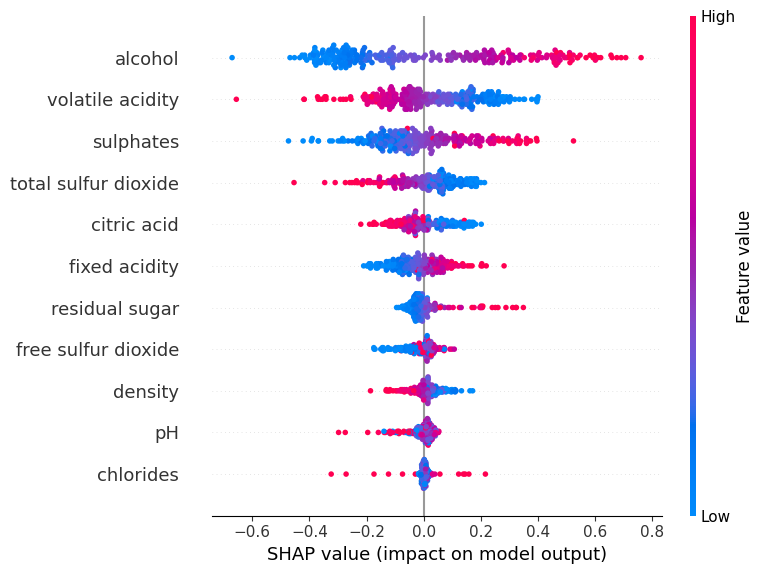


--- RUNNING REPRODUCIBLE SHAP FOR WHITE WINE SVR (nsamples=2046) ---


  0%|          | 0/793 [00:00<?, ?it/s]

Successfully backed up computed SHAP values to shap_vals_svr_white.npy


,Feature,Mean |SHAP|
Final_Rank,,
1,alcohol,0.255438
2,residual sugar,0.123688
3,density,0.103146
4,volatile acidity,0.095796
5,free sulfur dioxide,0.086958
6,pH,0.084631
7,total sulfur dioxide,0.069539
8,chlorides,0.050040
9,sulphates,0.040617


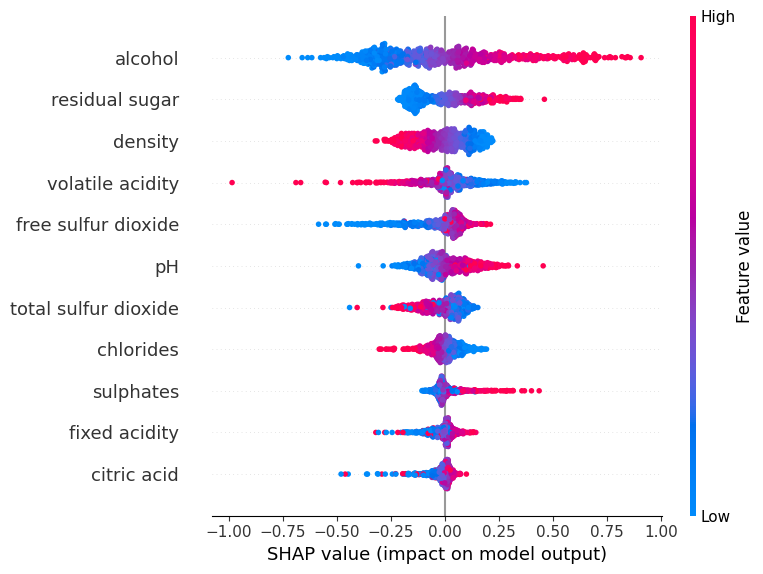

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)

# 1. Load data programmatically from cleaned sources
urls = {
    'red': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'white': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
}

red_clean = pd.read_csv(urls['red'], sep=';').drop_duplicates()
white_clean = pd.read_csv(urls['white'], sep=';').drop_duplicates()

# 2. Extract features and regression targets
X_red = red_clean.drop(columns=['quality'], errors='ignore')
y_red_reg = red_clean['quality']
X_white = white_clean.drop(columns=['quality'], errors='ignore')
y_white_reg = white_clean['quality']

# 3. Stratified Train-Test Split (80/20) matching R² configuration
def to_class(q):
    return np.where(q <= 4, 0, np.where(q <= 6, 1, 2))

y_red_cls = to_class(y_red_reg.values)
y_white_cls = to_class(y_white_reg.values)

X_red_train, X_red_test, y_red_reg_train, y_red_reg_test = train_test_split(
    X_red, y_red_reg, test_size=0.2, random_state=42, stratify=y_red_cls
)
X_white_train, X_white_test, y_white_reg_train, y_white_reg_test = train_test_split(
    X_white, y_white_reg, test_size=0.2, random_state=42, stratify=y_white_cls
)

# 4. Standardize features independently preserving original index
scaler_red = MinMaxScaler()
X_red_train_scaled = pd.DataFrame(scaler_red.fit_transform(X_red_train), columns=X_red_train.columns, index=X_red_train.index)
X_red_test_scaled = pd.DataFrame(scaler_red.transform(X_red_test), columns=X_red_test.columns, index=X_red_test.index)

scaler_white = MinMaxScaler()
X_white_train_scaled = pd.DataFrame(scaler_white.fit_transform(X_white_train), columns=X_white_train.columns, index=X_white_train.index)
X_white_test_scaled = pd.DataFrame(scaler_white.transform(X_white_test), columns=X_white_test.columns, index=X_white_test.index)

# 5. Fit SVR
svr_red = SVR(kernel='rbf', C=1.0, epsilon=0.1).fit(X_red_train_scaled, y_red_reg_train)
svr_white = SVR(kernel='rbf', C=1.0, epsilon=0.1).fit(X_white_train_scaled, y_white_reg_train)

# Validate model performance
preds_red = svr_red.predict(X_red_test_scaled)
preds_white = svr_white.predict(X_white_test_scaled)

print("=== VERIFYING MODEL BENCHMARKS ===")
print(f"Red Wine SVR  - MSE: {mean_squared_error(y_red_reg_test, preds_red):.4f} | R2: {r2_score(y_red_reg_test, preds_red):.4f}")
print(f"White Wine SVR - MSE: {mean_squared_error(y_white_reg_test, preds_white):.4f} | R2: {r2_score(y_white_reg_test, preds_white):.4f}")

# 6. Generate SVR SHAP with fixed seed and nsamples and plot the summary
def run_reproducible_svr_shap(model, X_train, X_test, label):
    print(f'\n--- RUNNING REPRODUCIBLE SHAP FOR {label.upper()} WINE SVR (nsamples=2046) ---')

    # Use K-means on the training data to get a stable background dataset
    background = shap.kmeans(X_train, 15)

    # Initialize the KernelExplainer with a deterministic background dataset
    explainer = shap.KernelExplainer(model.predict, background)

    # Compute SHAP values with explicitly controlled parameters
    shap_vals = explainer.shap_values(X_test, nsamples=2046, l1_reg='auto')

    # Backup SHAP values to disk to prevent re-running in the future
    np.save(f"shap_vals_svr_{label.lower()}.npy", shap_vals)
    print(f"Successfully backed up computed SHAP values to shap_vals_svr_{label.lower()}.npy")

    # Print table ranking
    mean_abs_shap = np.abs(shap_vals).mean(axis=0)
    rank_df = pd.DataFrame({
        'Feature': X_test.columns,
        'Mean |SHAP|': mean_abs_shap
    }).sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)
    rank_df.index = rank_df.index + 1
    rank_df.index.name = 'Final_Rank'
    display(rank_df)
    rank_df.to_csv(f'reproducible_shap_ranking_svr_{label.lower()}.csv')

    # Plot SVR SHAP summary (No Title, ready for LaTeX captions)
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_vals, X_test, show=False)
    plt.tight_layout()
    plt.savefig(f"{label.lower()}-svr.png", dpi=300, bbox_inches="tight")
    plt.show()

    return rank_df

# Compute reproducible SHAP rankings and plot summaries
reproducible_red = run_reproducible_svr_shap(svr_red, X_red_train_scaled, X_red_test_scaled, 'red')
reproducible_white = run_reproducible_svr_shap(svr_white, X_white_train_scaled, X_white_test_scaled, 'white')

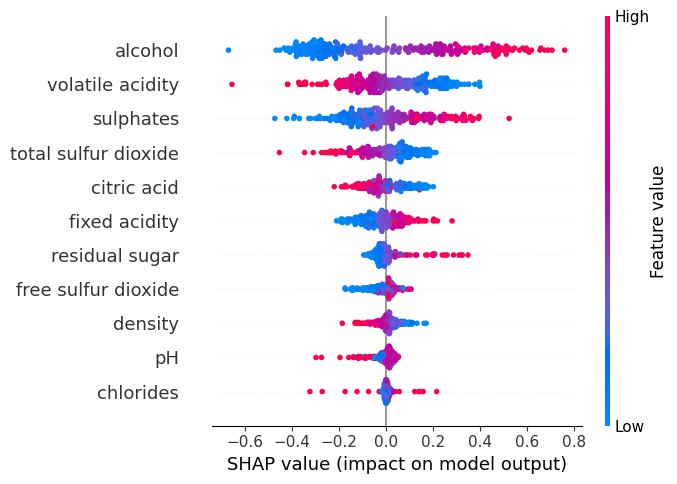

Successfully generated and saved red-svr.png


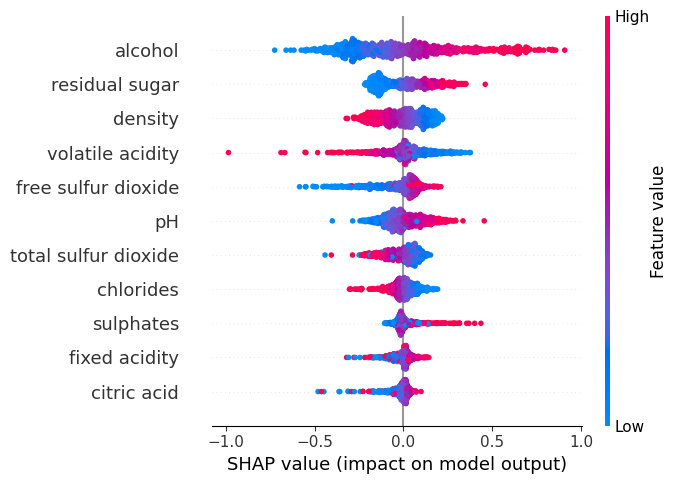

Successfully generated and saved white-svr.png


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

# Thiết lập cấu hình font chữ
plt.rcParams.update({"font.size": 12})

# 1. Tải và tiền xử lý dữ liệu để tái tạo đúng phân tách dữ liệu (giống ô 62eac7a4)
urls = {
    'red': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'white': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
}

red_clean = pd.read_csv(urls['red'], sep=';').drop_duplicates()
white_clean = pd.read_csv(urls['white'], sep=';').drop_duplicates()

X_red = red_clean.drop(columns=['quality'], errors='ignore')
y_red_reg = red_clean['quality']
X_white = white_clean.drop(columns=['quality'], errors='ignore')
y_white_reg = white_clean['quality']

def to_class(q):
    return np.where(q <= 4, 0, np.where(q <= 6, 1, 2))

y_red_cls = to_class(y_red_reg.values)
y_white_cls = to_class(y_white_reg.values)

# Chia tập Train-Test đồng bộ 80/20 với Stratify
_, X_red_test, _, _ = train_test_split(
    X_red, y_red_reg, test_size=0.2, random_state=42, stratify=y_red_cls
)
_, X_white_test, _, _ = train_test_split(
    X_white, y_white_reg, test_size=0.2, random_state=42, stratify=y_white_cls
)

# Chuẩn hóa độc lập MinMax sử dụng fit từ tập Train (tái lập dữ liệu test_scaled)
scaler_red = MinMaxScaler().fit(train_test_split(X_red, y_red_reg, test_size=0.2, random_state=42, stratify=y_red_cls)[0])
X_red_test_scaled = pd.DataFrame(scaler_red.transform(X_red_test), columns=X_red_test.columns, index=X_red_test.index)

scaler_white = MinMaxScaler().fit(train_test_split(X_white, y_white_reg, test_size=0.2, random_state=42, stratify=y_white_cls)[0])
X_white_test_scaled = pd.DataFrame(scaler_white.transform(X_white_test), columns=X_white_test.columns, index=X_white_test.index)

# Danh sách dữ liệu để vẽ biểu đồ
plots_config = [
    ("red", X_red_test_scaled),
    ("white", X_white_test_scaled)
]

for label, X in plots_config:
    try:
        # Tải giá trị SHAP đã được lưu từ trước
        sv = np.load(f"shap_vals_svr_{label}.npy")

        # Khởi tạo figure mới
        plt.figure()

        # Vẽ biểu đồ summary plot với kích thước chỉ định
        shap.summary_plot(sv, X, show=False, plot_size=(7, 5))

        # Tối ưu hóa bố cục và lưu ảnh chất lượng cao
        plt.tight_layout()
        plt.savefig(f"{label}-svr.png", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()
        print(f"Successfully generated and saved {label}-svr.png")
    except FileNotFoundError:
        print(f"Error: File shap_vals_svr_{label}.npy not found. Please run the SVR SHAP generation cell first.")


=== Feature Importance for RED WINE (Test set: 272 samples) ===
sulphates               0.2524
alcohol                 0.2289
volatile acidity        0.1537
citric acid             0.1165
total sulfur dioxide    0.0971
free sulfur dioxide     0.0935
pH                      0.0862
density                 0.0823
residual sugar          0.0644
fixed acidity           0.0626
chlorides               0.0440
dtype: float64


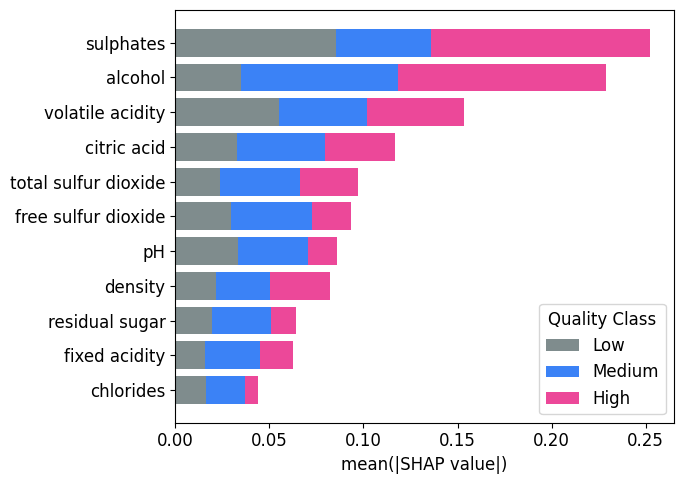


=== Feature Importance for WHITE WINE (Test set: 793 samples) ===
alcohol                 0.2168
free sulfur dioxide     0.1703
volatile acidity        0.1380
density                 0.1263
chlorides               0.1171
residual sugar          0.0981
total sulfur dioxide    0.0967
pH                      0.0736
citric acid             0.0681
fixed acidity           0.0619
sulphates               0.0503
dtype: float64


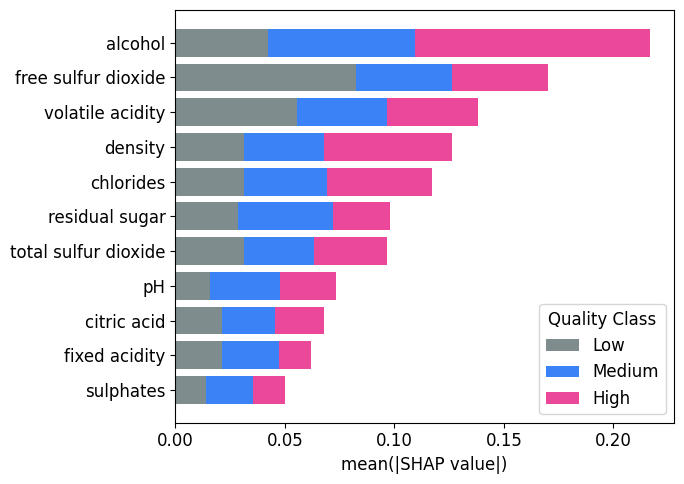

In [ ]:
import numpy as np, pandas as pd, shap, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE

# Sử dụng cùng nguồn dữ liệu chuẩn
urls = {
    'red': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'white': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
}
def to_class(q): return np.where(q <= 4, 0, np.where(q <= 6, 1, 2))

# Thiết lập cấu hình font chữ thống nhất
plt.rcParams.update({"font.size": 12})

for label in ['red', 'white']:
    df = pd.read_csv(urls[label], sep=';').drop_duplicates()
    X = df.drop(columns=['quality'])
    y = to_class(df['quality'].values)

    # Chia tách train-test có phân tầng 80/20 đồng bộ
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

    # Chuẩn hóa MinMax không rò rỉ thông tin
    sc = MinMaxScaler().fit(X_tr)
    X_tr_s = pd.DataFrame(sc.transform(X_tr), columns=X.columns, index=X_tr.index)
    X_te_s = pd.DataFrame(sc.transform(X_te), columns=X.columns, index=X_te.index)

    # Áp dụng SMOTE với k_neighbors=5 chỉ trên tập train
    X_res, y_res = SMOTE(random_state=42, k_neighbors=5).fit_resample(X_tr_s, y_tr)

    # Huấn luyện mô hình Random Forest
    rf = RandomForestClassifier(random_state=42).fit(X_res, y_res)

    # Tính toán TreeSHAP trên tập kiểm thử (held-out test set)
    sv = shap.TreeExplainer(rf).shap_values(X_te_s)
    np.save(f"shap_vals_rf_{label}.npy", np.array(sv))

    # Tính toán thứ hạng tầm quan trọng của các đặc trưng (Mean |SHAP|)
    arr = np.array(sv)
    imp = np.abs(arr).mean(axis=1).sum(axis=0) if isinstance(sv, list) else np.abs(arr).mean(axis=0).sum(axis=1)

    print(f"\n=== Feature Importance for {label.upper()} WINE (Test set: {len(X_te_s)} samples) ===")
    print(pd.Series(imp, index=X.columns).sort_values(ascending=False).round(4))

    # Vẽ biểu đồ summary dạng cột chồng với màu sắc cố định đồng nhất giữa các class
    per_class = np.stack([np.abs(s).mean(0) for s in sv], axis=1) if isinstance(sv, list) else np.abs(arr).mean(0)
    order = per_class.sum(1).argsort()

    colors = {'Low': '#7f8c8d', 'Medium': '#3b82f6', 'High': '#ec4899'}
    fig, ax = plt.subplots(figsize=(7, 5))
    left = np.zeros(len(order))
    for k, class_name in enumerate(['Low', 'Medium', 'High']):
        ax.barh(X.columns[order], per_class[order, k], left=left, color=colors[class_name], label=class_name)
        left += per_class[order, k]

    ax.set_xlabel('mean(|SHAP value|)')
    ax.legend(title="Quality Class")
    plt.tight_layout()
    plt.savefig(f"{label}-rf-treeshap.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()